In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv("../data/processed/job_market_cleaned.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()
df.shape
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   job_id                 30 non-null     int64  
 1   job_title              30 non-null     str    
 2   company                30 non-null     str    
 3   location               26 non-null     str    
 4   country                30 non-null     str    
 5   job_category           30 non-null     str    
 6   seniority_level        6 non-null      str    
 7   employment_type        30 non-null     str    
 8   work_arrangement       30 non-null     str    
 9   salary_min             2 non-null      float64
 10  salary_max             2 non-null      float64
 11  basic_salary           1 non-null      float64
 12  salary_period          3 non-null      str    
 13  currency               3 non-null      str    
 14  required_skills        29 non-null     str    
 15  preferred_skills   

In [6]:
df.shape


(30, 27)

In [7]:
df.dtypes

job_id                     int64
job_title                    str
company                      str
location                     str
country                      str
job_category                 str
seniority_level              str
employment_type              str
work_arrangement             str
salary_min               float64
salary_max               float64
basic_salary             float64
salary_period                str
currency                     str
required_skills              str
preferred_skills             str
qualification                str
experience                   str
cloud_platform               str
date_posted                  str
date_recorded                str
source                       str
job_url                      str
required_skills_list         str
preferred_skills_list        str
city                         str
cloud_platform_list          str
dtype: object

In [8]:
df.isnull().sum()

job_id                    0
job_title                 0
company                   0
location                  4
country                   0
job_category              0
seniority_level          24
employment_type           0
work_arrangement          0
salary_min               28
salary_max               28
basic_salary             29
salary_period            27
currency                 27
required_skills           1
preferred_skills          7
qualification            10
experience                4
cloud_platform           16
date_posted               0
date_recorded             0
source                    0
job_url                   0
required_skills_list      1
preferred_skills_list     7
city                      4
cloud_platform_list      16
dtype: int64

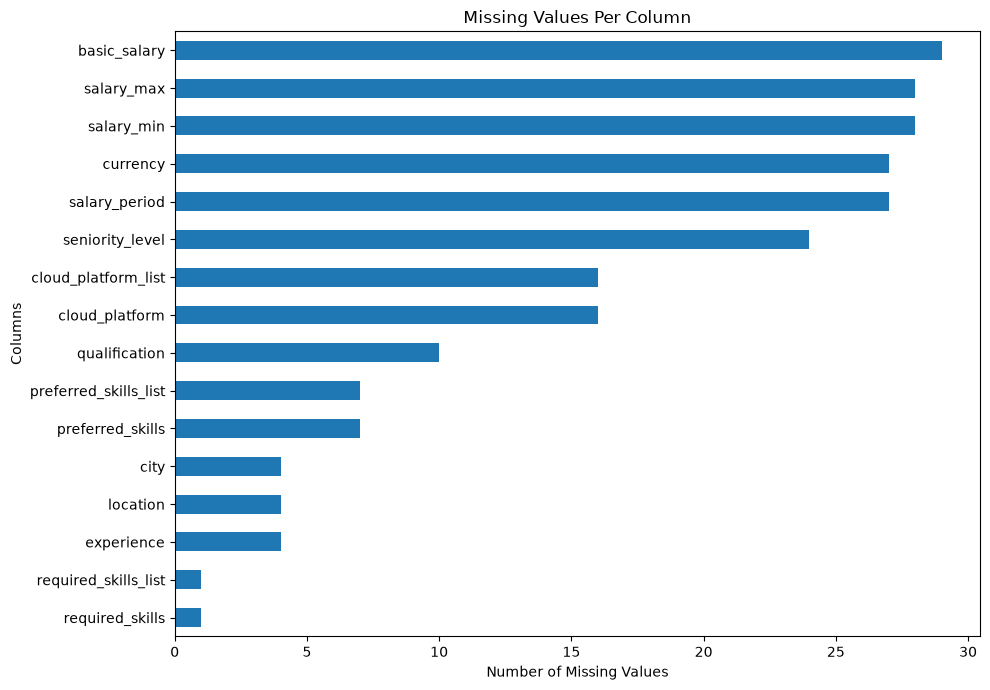

In [9]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values()

missing_values.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Missing Values Per Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

### Initial Dataset Inspection

The dataset contains **30 job advertisements and 27 columns**.

The initial inspection revealed missing values across several columns. Salary-related information had the highest proportion of missing values, with `basic_salary` missing in 29 out of 30 records.

Other columns with notable missing values include `seniority_level` (24), `salary_min` (28), `salary_max` (28), and `cloud_platform` (16).

The `required_skills` column was almost complete, with only one missing value.

These findings highlight potential limitations when analysing salary trends, seniority requirements and cloud platform demand.

No additional records were removed during this initial inspection.

In [10]:
df.describe()

,job_id,salary_min,salary_max,basic_salary
count,30.000000,2.000000,2.000000,1.0
mean,15.500000,7075.000000,10550.000000,25000.0
std,8.803408,9227.743494,13930.003589,NaN
min,1.000000,550.000000,700.000000,25000.0
25%,8.250000,3812.500000,5625.000000,25000.0
50%,15.500000,7075.000000,10550.000000,25000.0
75%,22.750000,10337.500000,15475.000000,25000.0
max,30.000000,13600.000000,20400.000000,25000.0


In [11]:
df.describe(include="object")

C:\Users\Sinovuyo Busakwe\AppData\Local\Temp\ipykernel_4708\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,job_title,company,location,country,job_category,seniority_level,employment_type,work_arrangement,salary_period,currency,...,experience,cloud_platform,date_posted,date_recorded,source,job_url,required_skills_list,preferred_skills_list,city,cloud_platform_list
count,30,30,26,30,30,6,30,30,3,3,...,26,14,30,30,30,30,29,23,26,14
unique,15,29,9,1,3,3,2,3,2,2,...,9,7,8,1,1,30,29,23,6,6
top,Data Engineer,Unifi Africa,Johannesburg,South Africa,Data Engineering,Senior,Full-Time,On-site,Monthly,ZAR,...,5+,"Microsoft Azure, AWS, Google Cloud Platform (GCP)",2 weeks ago,2026-11-18,LinkedIn,https://www.linkedin.com/jobs/view/4484476441/,"['Google Sheets', 'Data Analysis', 'Data Liter...","['Google Analytics 4 (GA4)', 'HubSpot', 'Marke...",Johannesburg,"['AWS', 'Google Cloud Platform (GCP)', 'Micros..."
freq,11,2,10,30,13,4,29,16,2,2,...,8,3,10,30,30,1,1,1,12,5


In [12]:
pd.set_option("display.max_columns", None)

df.describe(include="object").T

C:\Users\Sinovuyo Busakwe\AppData\Local\Temp\ipykernel_4708\149814061.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
job_title,30,15,Data Engineer,11
company,30,29,Unifi Africa,2
location,26,9,Johannesburg,10
country,30,1,South Africa,30
job_category,30,3,Data Engineering,13
seniority_level,6,3,Senior,4
employment_type,30,2,Full-Time,29
work_arrangement,30,3,On-site,16
salary_period,3,2,Monthly,2
currency,3,2,ZAR,2


### Categorical Descriptive Statistics

The categorical analysis revealed several characteristics of the collected job advertisements.

- Data Engineering was the most represented job category, accounting for 13 of the 30 advertisements.
- Full-Time employment was dominant, appearing in 29 advertisements.
- On-site work was the most common arrangement, appearing in 16 advertisements.
- Johannesburg was the most frequently recorded location.
- The most common experience requirement was 5+ years.
- The dataset contained 29 unique companies, with Unifi Africa appearing twice.
- All 30 advertisements were collected from LinkedIn and related to South African opportunities.

These observations provide an initial understanding of the job market sample. Further analysis is required to investigate skill demand, differences between job categories and relationships between variables.

In [13]:
df["job_category"].value_counts()

job_category
Data Engineering    13
Data Analyst        11
Data Science         6
Name: count, dtype: int64

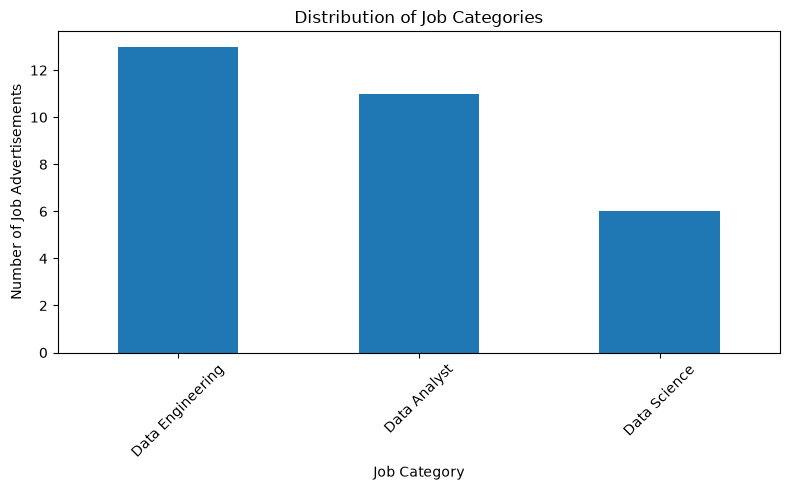

In [14]:
df["job_category"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Job Categories")
plt.xlabel("Job Category")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Job Category Distribution

The bar chart illustrates the distribution of job advertisements across three categories.

Data Engineering represents the largest category, with 13 advertisements (43.3%), followed by Data Analyst with 11 advertisements (36.7%). Data Science has the smallest representation, with 6 advertisements (20%).

This indicates that Data Engineering is the most represented job category in the collected sample.

In [15]:
df["work_arrangement"].value_counts()

work_arrangement
On-site    16
Hybrid     12
Remote      2
Name: count, dtype: int64

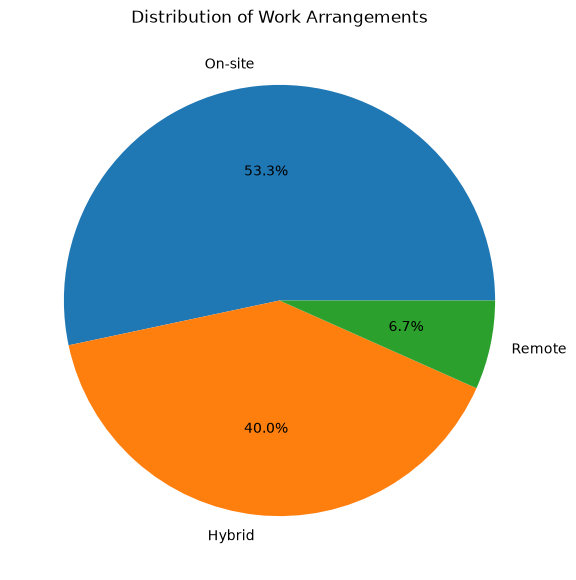

In [16]:
df["work_arrangement"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Distribution of Work Arrangements")
plt.ylabel("")
plt.show()

### Work Arrangement Distribution

The pie chart illustrates the distribution of work arrangements across the 30 job advertisements.

- **On-site:** 16 advertisements (53.3%)
- **Hybrid:** 12 advertisements (40.0%)
- **Remote:** 2 advertisements (6.7%)

On-site positions represent the largest proportion of the sample, followed by hybrid positions. Remote opportunities are significantly less common.

This suggests that most advertised data-related positions in the collected sample require either on-site or hybrid work arrangements.

In [17]:
df["experience"].value_counts()

experience
5+    8
3+    7
4+    3
1+    2
7+    2
0+    1
2+    1
8+    1
6+    1
Name: count, dtype: int64

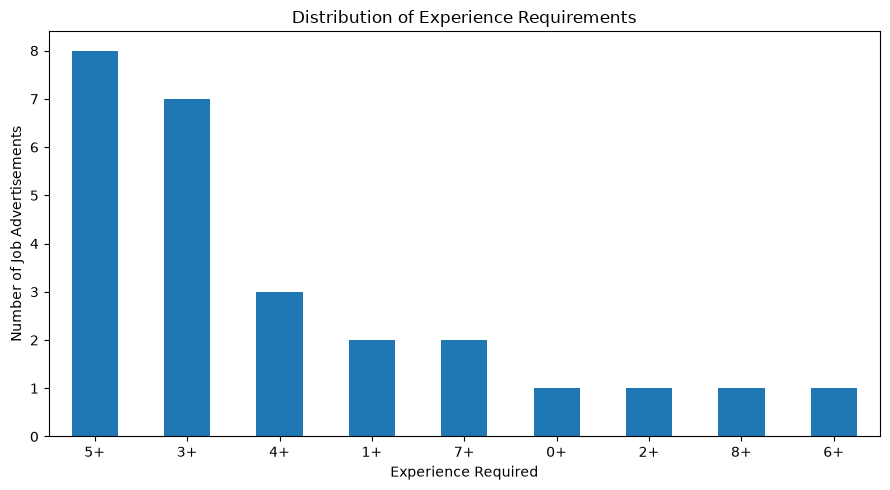

In [18]:
df["experience"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Experience Requirements")
plt.xlabel("Experience Required")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Experience Requirements Distribution

The bar chart illustrates the experience requirements across the 30 job advertisements.

The most frequently requested experience level is **5+ years**, appearing in 8 advertisements, followed by **3+ years**, appearing in 7 advertisements.

Other requirements include 4+ years (3 advertisements), 1+ years (2), and 7+ years (2). The remaining experience categories each appear once.

Four advertisements do not specify an experience requirement.

Overall, the sample suggests that employers frequently request candidates with at least three years of experience. Entry-level opportunities appear limited in the collected data.

In [19]:
df["qualification"].value_counts()

qualification
BCom Informatics, BSc Computer Science,BSc Data Science                                                                                                                                                                                                                                           1
Relevant Analytics or Design Qualification                                                                                                                                                                                                                                                        1
Relevant Quantitative Qualification or Equivalent Demonstrated Capability                                                                                                                                                                                                                         1
Bachelor's Degree or Diploma in Data Analytics, Statistics, Mathematics, Business Intelligence, Information Sy

### Qualification Requirements

Out of the 30 job advertisements, 20 contained qualification information, while 10 had missing values.

The dataset contains 20 unique qualification descriptions, with each description appearing only once.

Although the descriptions differ, several advertisements mention qualifications in Computer Science, Information Technology, Mathematics, Statistics and Data Analytics.

This variation makes it difficult to identify the most commonly requested qualification using simple frequency counts. Further analysis would be needed to group similar qualifications into broader categories.

In [21]:
df["employment_type"].value_counts()

employment_type
Full-Time    29
Contract      1
Name: count, dtype: int64

### Employment Type Distribution

The dataset contains 29 full-time positions (96.7%) and 1 contract position (3.3%).

Full-time employment dominates the collected job advertisements, while contract opportunities are very limited.

No part-time positions were identified in the sample.

This suggests that the advertised data-related opportunities are predominantly full-time roles.

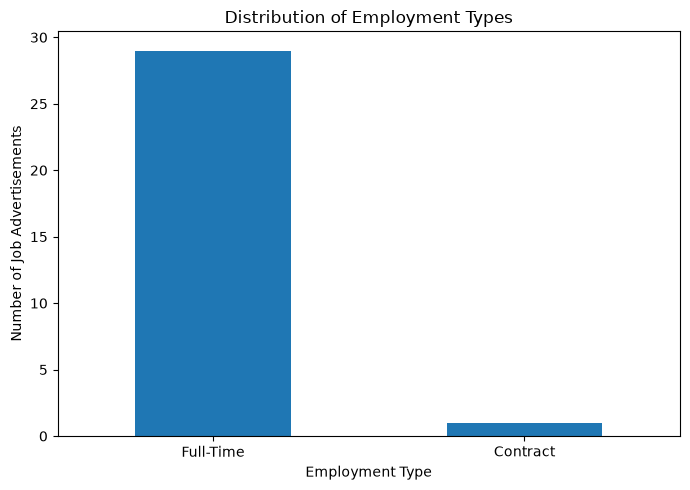

In [22]:
df["employment_type"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribution of Employment Types")
plt.xlabel("Employment Type")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
df["required_skills"].head(5)

0    Google Sheets, Data Analysis, Data Literacy, E...
1                                      Microsoft Excel
2    SQL, Payment Lifecycle Knowledge, Transactiona...
3    Problem Solving, Critical Thinking, Analytical...
4    SQL, Relational Database Management, Financial...
Name: required_skills, dtype: str

In [24]:
df["required_skills_list"].head(5)

0    ['Google Sheets', 'Data Analysis', 'Data Liter...
1                                  ['Microsoft Excel']
2    ['SQL', 'Payment Lifecycle Knowledge', 'Transa...
3    ['Problem Solving', 'Critical Thinking', 'Anal...
4    ['SQL', 'Relational Database Management', 'Fin...
Name: required_skills_list, dtype: str

In [25]:
type(df["required_skills_list"].iloc[0])

str

In [26]:
import ast

required_skills = df["required_skills_list"].dropna().apply(ast.literal_eval)

In [27]:
type(required_skills.iloc[0])

list

In [28]:
all_required_skills = [
    skill
    for job_skills in required_skills
    for skill in job_skills
]

In [29]:
from collections import Counter

required_skills_count = Counter(all_required_skills)

required_skills_count

Counter({'SQL': 16,
         'Python': 16,
         'Data Analysis': 15,
         'Data Modelling': 13,
         'Data Governance': 12,
         'Dashboard Development': 11,
         'Data Quality Management': 11,
         'Data Engineering': 11,
         'Data Warehousing': 11,
         'Data Visualisation': 10,
         'ETL': 10,
         'Data Validation': 8,
         'Data Integration': 8,
         'Stakeholder Management': 7,
         'Data Management': 7,
         'Data Pipelines': 7,
         'Database Management': 7,
         'Attention to Detail': 6,
         'API Integration': 6,
         'Data Transformation': 6,
         'ELT': 6,
         'Data Architecture': 6,
         'CI/CD': 6,
         'Technical Documentation': 6,
         'Communication': 5,
         'Problem Solving': 5,
         'Reporting': 5,
         'Google Cloud Platform (GCP)': 5,
         'Microsoft SQL Server': 5,
         'AWS': 5,
         'Microsoft Azure': 5,
         'Database Performance Tuning': 5

In [30]:
required_skills_series = pd.Series(required_skills_count)

top_15_required = required_skills_series.sort_values(
    ascending=False
).head(15)

top_15_required

Python                     16
SQL                        16
Data Analysis              15
Data Modelling             13
Data Governance            12
Data Quality Management    11
Dashboard Development      11
Data Warehousing           11
Data Engineering           11
Data Visualisation         10
ETL                        10
Data Validation             8
Data Integration            8
Data Pipelines              7
Database Management         7
dtype: int64

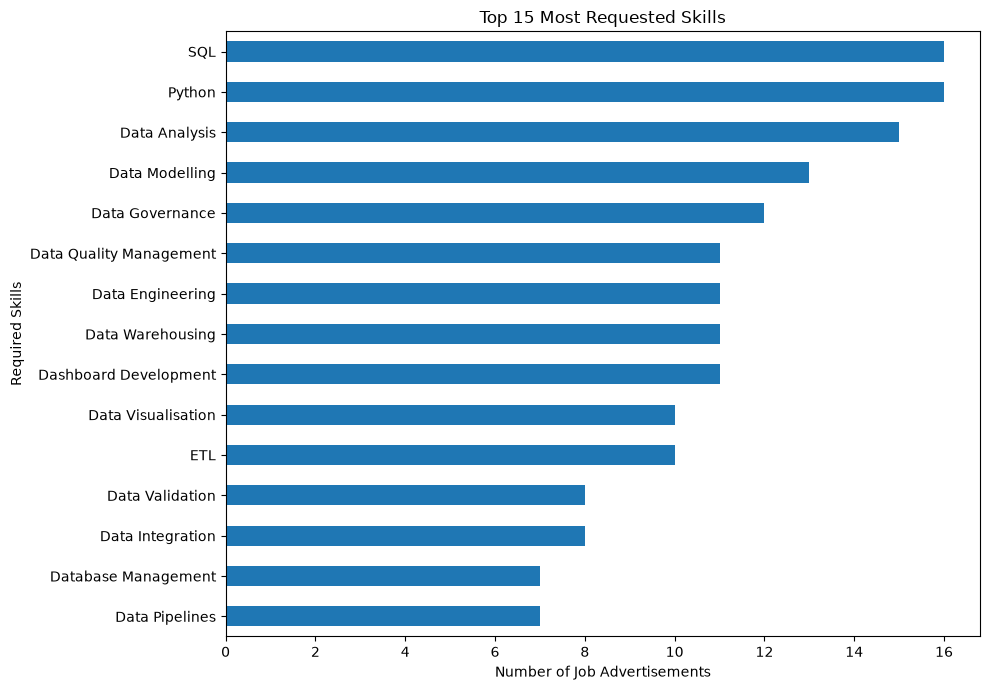

In [31]:
top_15_required.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top 15 Most Requested Skills")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Required Skills")
plt.tight_layout()
plt.show()

### Top 15 Most Requested Skills

The horizontal bar chart illustrates the 15 most frequently requested skills across the 30 job advertisements.

The most frequently requested skills are **Python and SQL**, each appearing in 16 advertisements, followed by **Data Analysis** (15), **Data Modelling** (13) and **Data Governance** (12).

Other prominent skills include Data Quality Management, Dashboard Development, Data Warehousing and Data Engineering, each appearing in 11 advertisements.

These findings suggest that employers value a combination of programming, analytical and data management skills.

Python and SQL stand out as particularly important technical skills, while Data Analysis highlights the importance of interpreting and working with data. The demand for Data Modelling, Data Governance and Data Warehousing also suggests that employers value the ability to manage, structure and maintain reliable data systems.

Overall, the results indicate that aspiring data professionals should develop a combination of technical programming skills and broader data management capabilities.

In [32]:
df["preferred_skills_list"].head(5)

0    ['Google Analytics 4 (GA4)', 'HubSpot', 'Marke...
1                                                  NaN
2                      ['South African Payment Rails']
3    ['SQL', 'Python', 'Microsoft Power BI', 'Datab...
4    ['Direct Marketing', 'Call Center Campaign Man...
Name: preferred_skills_list, dtype: str

In [33]:
preferred_skills = df["preferred_skills_list"].dropna().apply(ast.literal_eval)

In [34]:
type(preferred_skills.iloc[0])

list

In [35]:
all_preferred_skills = [
    skill
    for job_skills in preferred_skills
    for skill in job_skills
]

In [36]:
preferred_skills_count = Counter(all_preferred_skills)

preferred_skills_count

Counter({'Power BI': 5,
         'Python': 4,
         'Tableau': 4,
         'Snowflake': 3,
         'Apache Airflow': 3,
         'Financial Services Knowledge': 3,
         'A/B Testing': 2,
         'SQL': 2,
         'Databricks': 2,
         'Data Visualisation': 2,
         'Retail Analytics': 2,
         'dbt': 2,
         'Looker': 2,
         'Transactional Data Analysis': 2,
         'Microsoft Azure': 2,
         'Microsoft Fabric': 2,
         'Apache Kafka': 2,
         'Healthcare Data Analytics': 2,
         'Google Analytics 4 (GA4)': 1,
         'HubSpot': 1,
         'Marketo': 1,
         'Salesforce': 1,
         'Data Anomaly Detection': 1,
         'Root Cause Analysis': 1,
         'Requirements Gathering': 1,
         'Conversion Rate Optimisation (CRO)': 1,
         'South African Payment Rails': 1,
         'Microsoft Power BI': 1,
         'Power Query': 1,
         'Database Concepts': 1,
         'Data Transformation': 1,
         'Data Automation': 1,
  

In [37]:
preferred_skills_series = pd.Series(preferred_skills_count)

top_15_preferred = preferred_skills_series.sort_values(
    ascending=False
).head(15)

top_15_preferred

Power BI                        5
Tableau                         4
Python                          4
Snowflake                       3
Apache Airflow                  3
Financial Services Knowledge    3
Retail Analytics                2
Data Visualisation              2
SQL                             2
Transactional Data Analysis     2
Looker                          2
dbt                             2
A/B Testing                     2
Apache Kafka                    2
Microsoft Fabric                2
dtype: int64

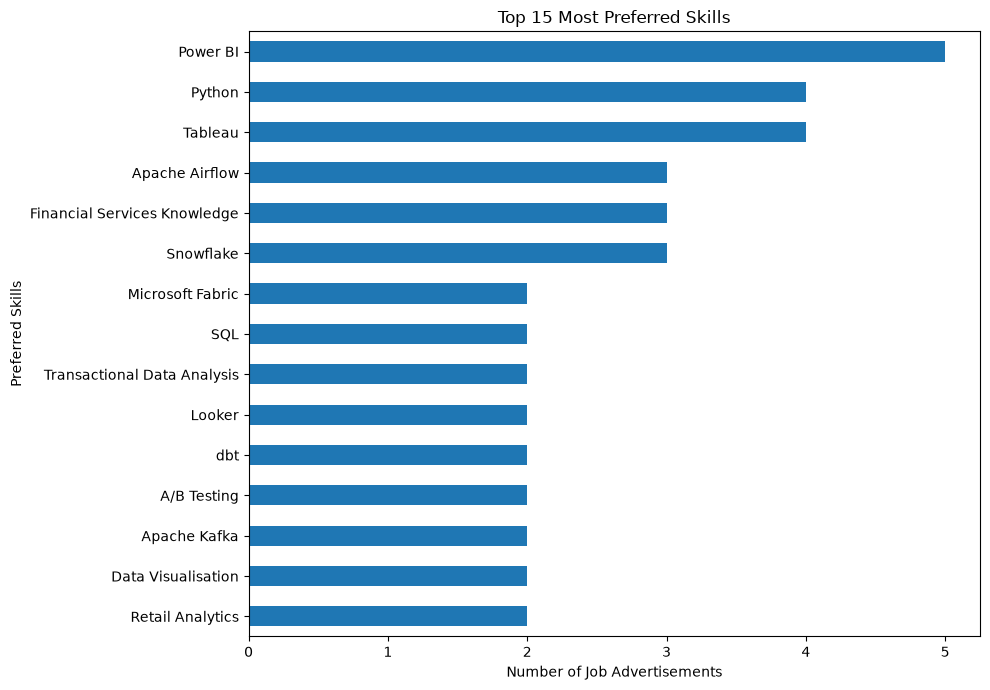

In [38]:
top_15_preferred.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top 15 Most Preferred Skills")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Preferred Skills")
plt.tight_layout()
plt.show()

### Top 15 Most Preferred Skills

The horizontal bar chart illustrates the 15 most frequently mentioned preferred skills across the job advertisements.

**Power BI** is the most frequently mentioned preferred skill, appearing in 5 advertisements. Tableau and Python follow with 4 mentions each. Snowflake, Apache Airflow and Financial Services Knowledge each appear in 3 advertisements.

Other notable skills include Retail Analytics, Data Visualisation, SQL, Looker, dbt, A/B Testing, Apache Kafka and Microsoft Fabric.

These findings suggest that employers value additional proficiency in business intelligence tools, data visualisation platforms, cloud data technologies and specialised industry knowledge.

Power BI, Python and SQL are particularly interesting because they also appear among the most frequently requested required skills.

Preferred skills may provide candidates with a competitive advantage, even when they are not essential requirements for a position.

In [39]:
print("Unique required skills:", len(required_skills_count))
print("Unique preferred skills:", len(preferred_skills_count))

Unique required skills: 403
Unique preferred skills: 189


### Comparison of Required and Preferred Skills

The analysis identified 403 unique required skills and 189 unique preferred skills across the collected job advertisements.

The required skills category contains more than twice as many distinct skills as the preferred skills category.

This suggests that job advertisements specify a broader range of mandatory competencies, while preferred skills tend to highlight additional tools, technologies and specialised knowledge.

However, the number of unique skills does not indicate how frequently employers request them. Frequency analysis is necessary to understand which individual skills are most common.

In [40]:
common_skills = set(required_skills_count.keys()) & set(preferred_skills_count.keys())

print("Skills appearing in both categories:", len(common_skills))

Skills appearing in both categories: 62


In [41]:
common_skills

{'A/B Testing',
 'API Integration',
 'AWS',
 'AWS Glue',
 'Ab Initio',
 'Analytical Thinking',
 'Apache Airflow',
 'Apache Spark',
 'Attention to Detail',
 'Azure Data Factory (ADF)',
 'Communication',
 'Customer Segmentation',
 'Data Analysis',
 'Data Automation',
 'Data Documentation',
 'Data Governance',
 'Data Integration',
 'Data Interpretation',
 'Data Lakes',
 'Data Migration',
 'Data Modelling',
 'Data Privacy',
 'Data Reconciliation',
 'Data Storytelling',
 'Data Transformation',
 'Data Validation',
 'Data Visualisation',
 'Data Warehousing',
 'Databricks',
 'Feature Engineering',
 'Google BigQuery',
 'Google Cloud Platform (GCP)',
 'Infrastructure as Code (IaC)',
 'Java',
 'Jira',
 'KPI Development',
 'Looker',
 'Microsoft Azure',
 'Microsoft Excel (Advanced)',
 'Microsoft Power BI',
 'Model Deployment',
 'Power BI',
 'Power Query',
 'Presentation Skills',
 'Prioritisation',
 'Problem Solving',
 'Process Optimisation',
 'PySpark',
 'Python',
 'Qlik Sense',
 'Real-Time Data St

In [42]:
sorted(common_skills)

['A/B Testing',
 'API Integration',
 'AWS',
 'AWS Glue',
 'Ab Initio',
 'Analytical Thinking',
 'Apache Airflow',
 'Apache Spark',
 'Attention to Detail',
 'Azure Data Factory (ADF)',
 'Communication',
 'Customer Segmentation',
 'Data Analysis',
 'Data Automation',
 'Data Documentation',
 'Data Governance',
 'Data Integration',
 'Data Interpretation',
 'Data Lakes',
 'Data Migration',
 'Data Modelling',
 'Data Privacy',
 'Data Reconciliation',
 'Data Storytelling',
 'Data Transformation',
 'Data Validation',
 'Data Visualisation',
 'Data Warehousing',
 'Databricks',
 'Feature Engineering',
 'Google BigQuery',
 'Google Cloud Platform (GCP)',
 'Infrastructure as Code (IaC)',
 'Java',
 'Jira',
 'KPI Development',
 'Looker',
 'Microsoft Azure',
 'Microsoft Excel (Advanced)',
 'Microsoft Power BI',
 'Model Deployment',
 'Power BI',
 'Power Query',
 'Presentation Skills',
 'Prioritisation',
 'Problem Solving',
 'Process Optimisation',
 'PySpark',
 'Python',
 'Qlik Sense',
 'Real-Time Data St

In [43]:
for skill in sorted(common_skills):
    print(skill)

A/B Testing
API Integration
AWS
AWS Glue
Ab Initio
Analytical Thinking
Apache Airflow
Apache Spark
Attention to Detail
Azure Data Factory (ADF)
Communication
Customer Segmentation
Data Analysis
Data Automation
Data Documentation
Data Governance
Data Integration
Data Interpretation
Data Lakes
Data Migration
Data Modelling
Data Privacy
Data Reconciliation
Data Storytelling
Data Transformation
Data Validation
Data Visualisation
Data Warehousing
Databricks
Feature Engineering
Google BigQuery
Google Cloud Platform (GCP)
Infrastructure as Code (IaC)
Java
Jira
KPI Development
Looker
Microsoft Azure
Microsoft Excel (Advanced)
Microsoft Power BI
Model Deployment
Power BI
Power Query
Presentation Skills
Prioritisation
Problem Solving
Process Optimisation
PySpark
Python
Qlik Sense
Real-Time Data Streaming
Reporting Automation
Root Cause Analysis
SAS
SAS ETL
SQL
Snowflake
Stakeholder Management
Statistical Analysis
Time Management
Transactional Data Analysis
dbt


In [44]:
common_skills_comparison = pd.DataFrame({
    "Required": {
        skill: required_skills_count[skill]
        for skill in common_skills
    },
    "Preferred": {
        skill: preferred_skills_count[skill]
        for skill in common_skills
    }
})

common_skills_comparison

,Required,Preferred
Customer Segmentation,2,1
Data Integration,8,1
Model Deployment,1,1
Data Analysis,15,1
Qlik Sense,1,1
...,...,...
Infrastructure as Code (IaC),3,1
Problem Solving,5,1
Data Validation,8,1
Attention to Detail,6,1


In [45]:
common_skills_comparison.sort_values(
    by="Preferred",
    ascending=False
).head(15)

,Required,Preferred
Power BI,4,5
Python,16,4
Apache Airflow,1,3
Snowflake,2,3
A/B Testing,1,2
Looker,1,2
Microsoft Azure,5,2
SQL,16,2
dbt,1,2
Transactional Data Analysis,1,2


### Comparison of Required and Preferred Skills

The comparison identified 62 skills appearing in both the required and preferred skills categories.

Python and SQL are among the strongest required skills, appearing in 16 advertisements each as requirements. Data Analysis and Data Governance are also frequently required.

Power BI appears more frequently as a preferred skill (5 advertisements) than as a required skill (4 advertisements). Apache Airflow and Snowflake also appear more frequently as preferred skills.

In contrast, Data Visualisation and Data Governance are more frequently listed as required competencies.

These findings suggest that employers place strong emphasis on programming, analytical and data management skills, while tools such as Power BI, Snowflake and Apache Airflow can provide additional advantages.

The distinction between required and preferred skills varies across employers and job advertisements.

In [46]:
data_analyst_jobs = df[df["job_category"] == "Data Analyst"]

print("Number of Data Analyst jobs:", len(data_analyst_jobs))

Number of Data Analyst jobs: 11


In [47]:
analyst_skills = data_analyst_jobs["required_skills_list"].dropna().apply(ast.literal_eval)

In [48]:
all_analyst_skills = [
    skill
    for job_skills in analyst_skills
    for skill in job_skills
]

In [49]:
analyst_skills_count = Counter(all_analyst_skills)

analyst_skills_count

Counter({'Data Analysis': 6,
         'Attention to Detail': 6,
         'Communication': 5,
         'Dashboard Development': 5,
         'SQL': 4,
         'Problem Solving': 4,
         'Analytical Thinking': 4,
         'Data Visualisation': 4,
         'Data Modelling': 3,
         'Data Storytelling': 3,
         'Data Validation': 3,
         'Data Governance': 3,
         'Presentation Skills': 3,
         'Microsoft Excel': 2,
         'Time Management': 2,
         'Prioritisation': 2,
         'Customer Segmentation': 2,
         'Power BI': 2,
         'Python': 2,
         'Statistical Analysis': 2,
         'Trend Analysis': 2,
         'Data Collection': 2,
         'Data Cleaning': 2,
         'Reporting': 2,
         'Data Management': 2,
         'Data Documentation': 2,
         'Google Sheets': 1,
         'Data Literacy': 1,
         'English Communication': 1,
         'Payment Lifecycle Knowledge': 1,
         'Transactional Data Analysis': 1,
         'Business 

In [50]:
analyst_skills_series = pd.Series(analyst_skills_count)

top_analyst_skills = analyst_skills_series.sort_values(
    ascending=False
).head(10)

top_analyst_skills


Data Analysis            6
Attention to Detail      6
Communication            5
Dashboard Development    5
Problem Solving          4
Analytical Thinking      4
SQL                      4
Data Visualisation       4
Presentation Skills      3
Data Storytelling        3
dtype: int64

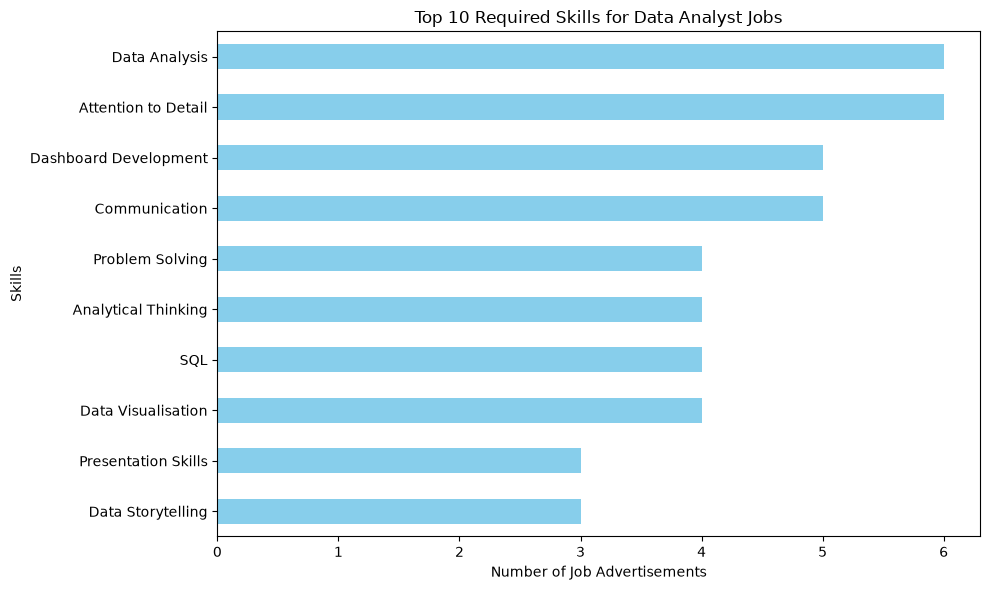

In [51]:
plt.figure(figsize=(10, 6))

top_analyst_skills.sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Top 10 Required Skills for Data Analyst Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

### Top 10 Required Skills for Data Analyst Jobs

The analysis examined the required skills listed across 11 Data Analyst job advertisements.

Data Analysis and Attention to Detail are the most frequently requested skills, each appearing in 6 advertisements. Communication and Dashboard Development follow, appearing in 5 advertisements each.

SQL, Problem Solving, Analytical Thinking and Data Visualisation each appear in 4 advertisements.

Presentation Skills and Data Storytelling also feature among the top 10, appearing in 3 advertisements each.

These findings suggest that Data Analyst positions require a combination of technical, analytical and interpersonal skills. Employers value the ability to analyse data, develop dashboards and communicate insights effectively.

The results also highlight the importance of attention to detail and problem-solving when working with data.

In [52]:
data_engineering_jobs = df[
    df["job_category"] == "Data Engineering"
]

print("Number of Data Engineering jobs:", len(data_engineering_jobs))

Number of Data Engineering jobs: 13


In [53]:
engineering_skills = data_engineering_jobs[
    "required_skills_list"
].dropna().apply(ast.literal_eval)

In [54]:
all_engineering_skills = [
    skill
    for job_skills in engineering_skills
    for skill in job_skills
]

In [55]:
engineering_skills_count = Counter(all_engineering_skills)

engineering_skills_count

Counter({'Data Warehousing': 11,
         'Data Engineering': 10,
         'ETL': 10,
         'Python': 10,
         'Data Quality Management': 9,
         'SQL': 9,
         'Data Modelling': 9,
         'Data Governance': 8,
         'Data Pipelines': 7,
         'Data Integration': 7,
         'Database Management': 6,
         'ELT': 6,
         'Microsoft SQL Server': 5,
         'AWS': 5,
         'Data Analysis': 5,
         'Data Architecture': 5,
         'API Integration': 5,
         'Data Management': 5,
         'CI/CD': 5,
         'Data Validation': 5,
         'SQL Server Integration Services (SSIS)': 4,
         'Microsoft Azure': 4,
         'Data Transformation': 4,
         'Database Performance Tuning': 4,
         'Dashboard Development': 4,
         'Data Pipeline Development': 4,
         'Advanced SQL': 3,
         'Database Administration': 3,
         'Metadata Management': 3,
         'Data Lineage': 3,
         'Google Cloud Platform (GCP)': 3,
         'A

In [56]:
engineering_skills_series = pd.Series(engineering_skills_count)

top_engineering_skills = engineering_skills_series.sort_values(
    ascending=False
).head(10)

top_engineering_skills

Data Warehousing           11
Data Engineering           10
ETL                        10
Python                     10
Data Quality Management     9
Data Modelling              9
SQL                         9
Data Governance             8
Data Integration            7
Data Pipelines              7
dtype: int64

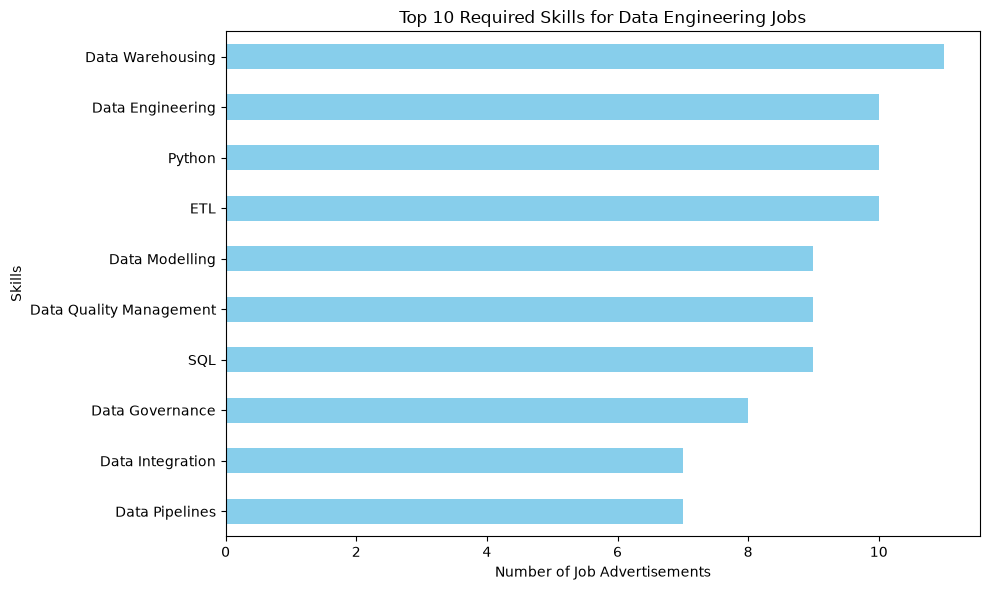

In [57]:
plt.figure(figsize=(10, 6))

top_engineering_skills.sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Top 10 Required Skills for Data Engineering Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()


### Top 10 Required Skills for Data Engineering Jobs

The analysis examined the required skills listed across 13 Data Engineering job advertisements.

Data Warehousing is the most frequently requested skill, appearing in 11 advertisements. Data Engineering, ETL and Python follow, each appearing in 10 advertisements.

Data Quality Management, Data Modelling and SQL each appear in 9 advertisements, while Data Governance appears in 8.

Data Integration and Data Pipelines also feature prominently, each appearing in 7 advertisements.

These findings suggest that Data Engineering positions place strong emphasis on building, managing and maintaining data infrastructure.

Employers value skills related to data warehousing, ETL processes, data pipelines, programming and database management. Python and SQL are also important technical skills within this category.

Overall, the results highlight the importance of data processing, integration and infrastructure skills for aspiring Data Engineers.

In [58]:
data_science_jobs = df[
    df["job_category"] == "Data Science"
]

print("Number of Data Science jobs:", len(data_science_jobs))


Number of Data Science jobs: 6


In [59]:
science_skills = data_science_jobs[
    "required_skills_list"
].dropna().apply(ast.literal_eval)


In [60]:
all_science_skills = [
    skill
    for job_skills in science_skills
    for skill in job_skills
]

In [61]:
science_skills_count = Counter(all_science_skills)

science_skills_count

Counter({'Data Analysis': 4,
         'Python': 4,
         'Data Visualisation': 3,
         'SQL': 3,
         'Stakeholder Management': 3,
         'Technical Documentation': 3,
         'Statistical Modelling': 2,
         'Predictive Modelling': 2,
         'Machine Learning': 2,
         'Machine Learning Algorithms': 2,
         'Model Evaluation': 2,
         'Requirements Analysis': 2,
         'Generative AI (GenAI)': 2,
         'Data Science': 2,
         'Data-Driven Decision-Making': 2,
         'R': 2,
         'Dashboard Development': 2,
         'Prescriptive Modelling': 1,
         'Data Mining': 1,
         'Data Architecture': 1,
         'Enterprise Data Management': 1,
         'Database Management': 1,
         'Oracle Database': 1,
         'Cloud Computing': 1,
         'Cloud Data Platforms': 1,
         'Data Platform Management': 1,
         'Data Platform Security': 1,
         'Data Engineering': 1,
         'Data Modelling': 1,
         'Conceptual Data M

In [62]:
science_skills_series = pd.Series(science_skills_count)

top_science_skills = science_skills_series.sort_values(
    ascending=False
).head(10)

top_science_skills

Data Analysis                  4
Python                         4
SQL                            3
Data Visualisation             3
Technical Documentation        3
Stakeholder Management         3
Machine Learning Algorithms    2
Machine Learning               2
Model Evaluation               2
Data Science                   2
dtype: int64

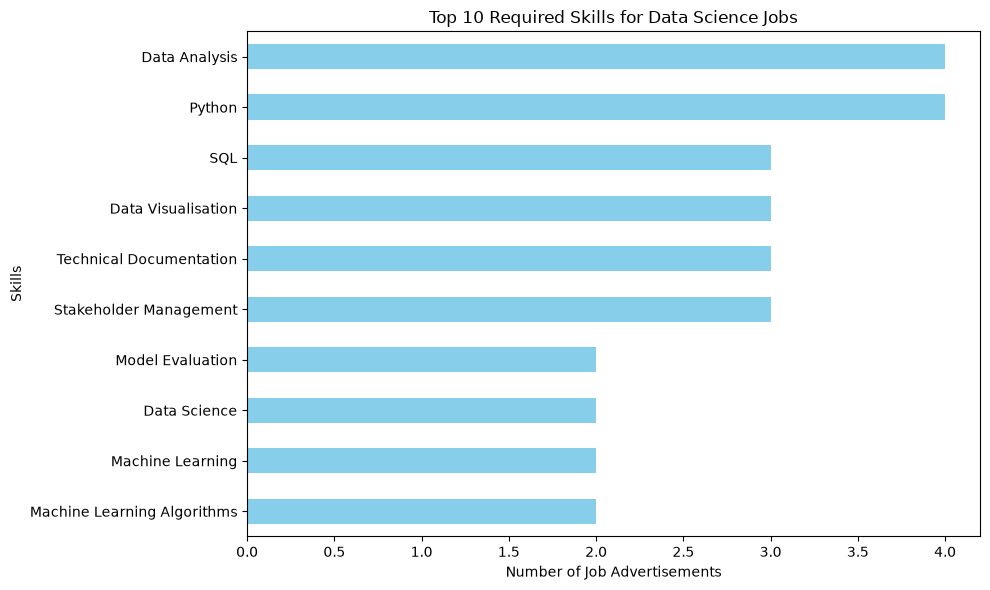

In [63]:
plt.figure(figsize=(10, 6))

top_science_skills.sort_values().plot(
    kind="barh",
    color="skyblue"
)

plt.title("Top 10 Required Skills for Data Science Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

### Top 10 Required Skills for Data Science Jobs

The analysis examined the required skills listed across 6 Data Science job advertisements.

Data Analysis and Python are the most frequently requested skills, each appearing in 4 advertisements.

SQL, Data Visualisation, Technical Documentation and Stakeholder Management follow, each appearing in 3 advertisements.

Machine Learning Algorithms, Machine Learning, Model Evaluation and Data Science each appear in 2 advertisements.

These findings suggest that Data Science positions require a combination of programming, analytical and machine learning capabilities.

Python and SQL are important technical foundations, while skills such as Machine Learning, Statistical Modelling and Model Evaluation highlight the importance of developing predictive and analytical solutions.

The results also demonstrate that communication-related competencies, including Technical Documentation and Stakeholder Management, are valuable in Data Science roles.

In [64]:
category_skills = pd.DataFrame({
    "Data Analyst": top_analyst_skills,
    "Data Engineering": top_engineering_skills,
    "Data Science": top_science_skills
})

category_skills

,Data Analyst,Data Engineering,Data Science
Analytical Thinking,4.0,NaN,NaN
Attention to Detail,6.0,NaN,NaN
Communication,5.0,NaN,NaN
Dashboard Development,5.0,NaN,NaN
Data Analysis,6.0,NaN,4.0
Data Engineering,NaN,10.0,NaN
Data Governance,NaN,8.0,NaN
Data Integration,NaN,7.0,NaN
Data Modelling,NaN,9.0,NaN
Data Pipelines,NaN,7.0,NaN


In [65]:
common_all_categories = (
    set(analyst_skills_count.keys())
    & set(engineering_skills_count.keys())
    & set(science_skills_count.keys())
)

print("Skills common to all three categories:", len(common_all_categories))

sorted(common_all_categories)

Skills common to all three categories: 14


['Dashboard Development',
 'Data Analysis',
 'Data Governance',
 'Data Modelling',
 'Data Processing',
 'Data Quality Management',
 'Data Transformation',
 'Data Visualisation',
 'Google Cloud Platform (GCP)',
 'Python',
 'Reporting',
 'SQL',
 'Stakeholder Communication',
 'Stakeholder Management']

In [66]:
shared_skills_comparison = pd.DataFrame({
    "Data Analyst": {
        skill: analyst_skills_count[skill]
        for skill in common_all_categories
    },
    "Data Engineering": {
        skill: engineering_skills_count[skill]
        for skill in common_all_categories
    },
    "Data Science": {
        skill: science_skills_count[skill]
        for skill in common_all_categories
    }
})

shared_skills_comparison = shared_skills_comparison.sort_values(
    by="Data Analyst",
    ascending=False
)

shared_skills_comparison

,Data Analyst,Data Engineering,Data Science
Data Analysis,6,5,4
Dashboard Development,5,4,2
Data Visualisation,4,3,3
SQL,4,9,3
Data Governance,3,8,1
Data Modelling,3,9,1
Python,2,10,4
Reporting,2,2,1
Stakeholder Communication,1,2,1
Data Processing,1,2,1


### Skills Common Across All Three Job Categories

The analysis identified 14 skills that appear in Data Analyst, Data Engineering and Data Science job advertisements.

These shared skills include Python, SQL, Data Analysis, Data Modelling, Data Governance, Data Quality Management, Data Visualisation and Dashboard Development.

Data Analysis is particularly prominent in Data Analyst advertisements, appearing in 6 jobs. Python and SQL are especially prominent in Data Engineering advertisements, appearing in 10 and 9 jobs respectively.

Data Engineering advertisements also show a strong emphasis on Data Modelling, Data Governance and Data Quality Management.

Data Visualisation appears across all three categories, highlighting the importance of communicating data insights regardless of career path.

These findings suggest that the three career paths share an important technical foundation, although the frequency of individual skills varies according to job responsibilities.

Developing transferable skills such as Python, SQL, Data Analysis and Data Visualisation can provide a useful foundation for pursuing different careers in the data industry.

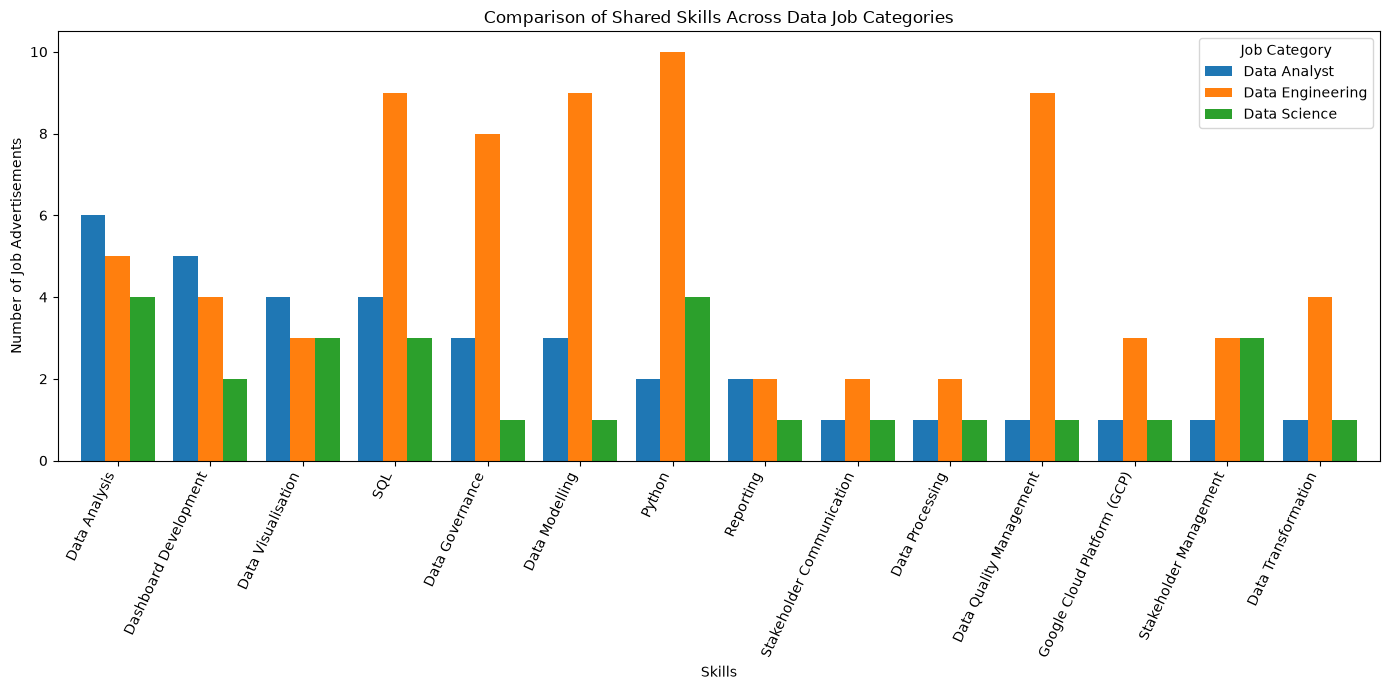

In [68]:
shared_skills_comparison.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Comparison of Shared Skills Across Data Job Categories")
plt.xlabel("Skills")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=65, ha="right")
plt.legend(title="Job Category")
plt.tight_layout()
plt.show()

In [69]:
analyst_preferred_skills = data_analyst_jobs[
    "preferred_skills_list"
].dropna().apply(ast.literal_eval)

In [70]:
all_analyst_preferred = [
    skill
    for job_skills in analyst_preferred_skills
    for skill in job_skills
]

In [71]:
analyst_preferred_count = Counter(all_analyst_preferred)

analyst_preferred_count

Counter({'Power BI': 3,
         'A/B Testing': 2,
         'SQL': 2,
         'Data Visualisation': 2,
         'Looker': 2,
         'Tableau': 2,
         'Google Analytics 4 (GA4)': 1,
         'HubSpot': 1,
         'Marketo': 1,
         'Salesforce': 1,
         'Data Anomaly Detection': 1,
         'Root Cause Analysis': 1,
         'Requirements Gathering': 1,
         'Conversion Rate Optimisation (CRO)': 1,
         'South African Payment Rails': 1,
         'Python': 1,
         'Microsoft Power BI': 1,
         'Databricks': 1,
         'Power Query': 1,
         'Database Concepts': 1,
         'Data Transformation': 1,
         'Data Automation': 1,
         'Artificial Intelligence (AI)': 1,
         'Direct Marketing': 1,
         'Call Center Campaign Management': 1,
         'Online Marketing': 1,
         'Retail Analytics': 1,
         'SAP BusinessObjects': 1,
         'Reporting Governance': 1,
         'Self-Service Analytics': 1,
         'Snowflake': 1,
      

In [72]:
analyst_preferred_series = pd.Series(analyst_preferred_count)

top_analyst_preferred = analyst_preferred_series.sort_values(
    ascending=False
).head(10)

top_analyst_preferred

Power BI                    3
SQL                         2
Data Visualisation          2
Tableau                     2
Looker                      2
A/B Testing                 2
Root Cause Analysis         1
Google Analytics 4 (GA4)    1
HubSpot                     1
Marketo                     1
dtype: int64

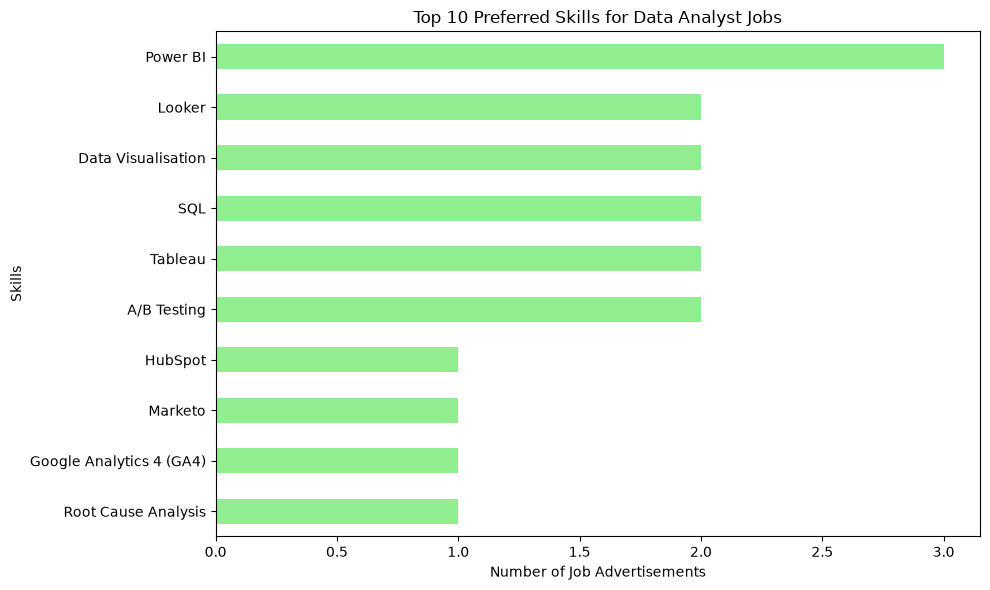

In [73]:
plt.figure(figsize=(10, 6))

top_analyst_preferred.sort_values().plot(
    kind="barh",
    color="lightgreen"
)

plt.title("Top 10 Preferred Skills for Data Analyst Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

### Top 10 Preferred Skills for Data Analyst Jobs

The analysis examined the preferred skills listed across Data Analyst job advertisements.

Power BI is the most frequently mentioned preferred skill, appearing in 3 advertisements.

SQL, Data Visualisation, Tableau, Looker and A/B Testing each appear in 2 advertisements.

Other preferred skills include Root Cause Analysis, Google Analytics 4, HubSpot and Marketo.

These findings suggest that employers value additional proficiency in business intelligence tools, data visualisation platforms and analytical techniques.

Power BI stands out as a particularly useful additional skill for Data Analyst candidates. Knowledge of tools such as Tableau and Looker may also provide a competitive advantage.

The results demonstrate that preferred skills can complement the technical and analytical competencies required for Data Analyst positions.

In [75]:
engineering_preferred_skills = data_engineering_jobs[
    "preferred_skills_list"
].dropna().apply(ast.literal_eval)

In [76]:
all_engineering_preferred = [
    skill
    for job_skills in engineering_preferred_skills
    for skill in job_skills
]


In [77]:
engineering_preferred_count = Counter(all_engineering_preferred)

engineering_preferred_count

Counter({'Apache Airflow': 3,
         'Python': 2,
         'Microsoft Fabric': 2,
         'Apache Kafka': 2,
         'Financial Services Knowledge': 2,
         'Power BI': 1,
         'SAP Data Services': 1,
         'Java': 1,
         'Linux Shell Scripting': 1,
         'Banking and Financial Services Knowledge': 1,
         'Regulated Industry Experience': 1,
         'QlikView': 1,
         'Visual Basic for Applications (VBA)': 1,
         'Jira': 1,
         'Slack': 1,
         'Fresh': 1,
         'Microsoft Project': 1,
         'Microsoft Visio': 1,
         'Mainframe Systems (MIP)': 1,
         'Microsoft Azure': 1,
         'Microsoft Power BI Certification': 1,
         'Azure Database Administration Certification': 1,
         'Microsoft Fabric Data Engineering Certification': 1,
         'PySpark': 1,
         'Apache Spark': 1,
         'dbt': 1,
         'Azure Data Factory (ADF)': 1,
         'Ab Initio': 1,
         'SAS ETL': 1,
         'Microsoft Logic Apps

In [78]:
engineering_preferred_series = pd.Series(engineering_preferred_count)

top_engineering_preferred = engineering_preferred_series.sort_values(
    ascending=False
).head(10)

top_engineering_preferred

Apache Airflow                   3
Microsoft Fabric                 2
Apache Kafka                     2
Financial Services Knowledge     2
Python                           2
SAP Data Services                1
Regulated Industry Experience    1
Power BI                         1
Linux Shell Scripting            1
Java                             1
dtype: int64

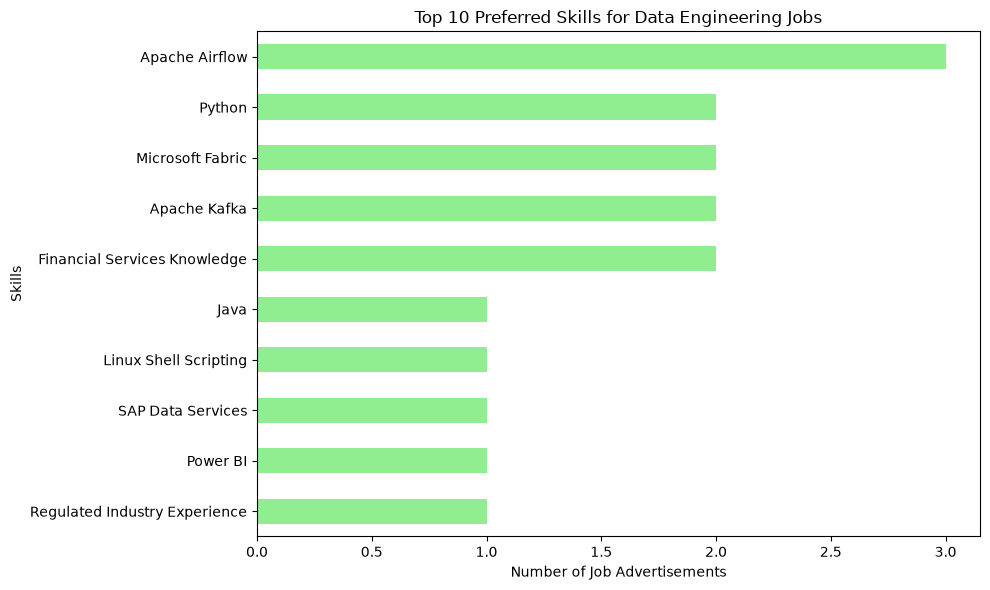

In [79]:
plt.figure(figsize=(10, 6))

top_engineering_preferred.sort_values().plot(
    kind="barh",
    color="lightgreen"
)

plt.title("Top 10 Preferred Skills for Data Engineering Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()


### Top 10 Preferred Skills for Data Engineering Jobs

The analysis examined the preferred skills listed across Data Engineering job advertisements.

Apache Airflow is the most frequently mentioned preferred skill, appearing in 3 advertisements.

Microsoft Fabric, Apache Kafka, Financial Services Knowledge and Python each appear in 2 advertisements.

Other preferred skills include SAP Data Services, Regulated Industry Experience, Power BI, Linux Shell Scripting and Java.

These findings suggest that employers value additional knowledge of data orchestration tools, big data technologies, cloud platforms and programming languages.

Apache Airflow stands out as an important additional technology for Data Engineering candidates because of its role in managing and scheduling data workflows.

Knowledge of tools such as Microsoft Fabric, Apache Kafka and Python may also provide a competitive advantage.

In [80]:
science_preferred_skills = data_science_jobs[
    "preferred_skills_list"
].dropna().apply(ast.literal_eval)


In [81]:
all_science_preferred = [
    skill
    for job_skills in science_preferred_skills
    for skill in job_skills
]

In [82]:
science_preferred_count = Counter(all_science_preferred)

science_preferred_count

Counter({'Healthcare Data Analytics': 2,
         'Fleet Management Systems': 1,
         'Telematics': 1,
         'Internet of Things (IoT)': 1,
         'Time-Series Data': 1,
         'Analytics Platforms': 1,
         'Microsoft Azure': 1,
         'AWS': 1,
         'Google Cloud Platform (GCP)': 1,
         'AI Cloud Deployment': 1,
         'Cloud Monitoring': 1,
         'Cloud Cost Management': 1,
         'AI Security': 1,
         'Data Privacy': 1,
         'Regulatory Compliance': 1,
         'Multi-Region Systems': 1,
         'Multilingual Systems': 1,
         'Healthcare Sector Knowledge': 1,
         'Healthcare Data Management': 1,
         'Python': 1,
         'SAS': 1,
         'Cloud Technologies': 1,
         'Posit Connect': 1,
         'Shiny Server': 1,
         'Real-World Data (RWD)': 1,
         'Clinical Trial Data Analysis': 1,
         'Health Technology Assessment (HTA)': 1,
         'Real-World Evidence (RWE)': 1,
         'Phase IIIb/IV Clinical Tri

In [83]:
science_preferred_series = pd.Series(science_preferred_count)

top_science_preferred = science_preferred_series.sort_values(
    ascending=False
).head(10)

top_science_preferred

Healthcare Data Analytics      2
Telematics                     1
Fleet Management Systems       1
Time-Series Data               1
Analytics Platforms            1
Microsoft Azure                1
Internet of Things (IoT)       1
AWS                            1
Google Cloud Platform (GCP)    1
Cloud Monitoring               1
dtype: int64

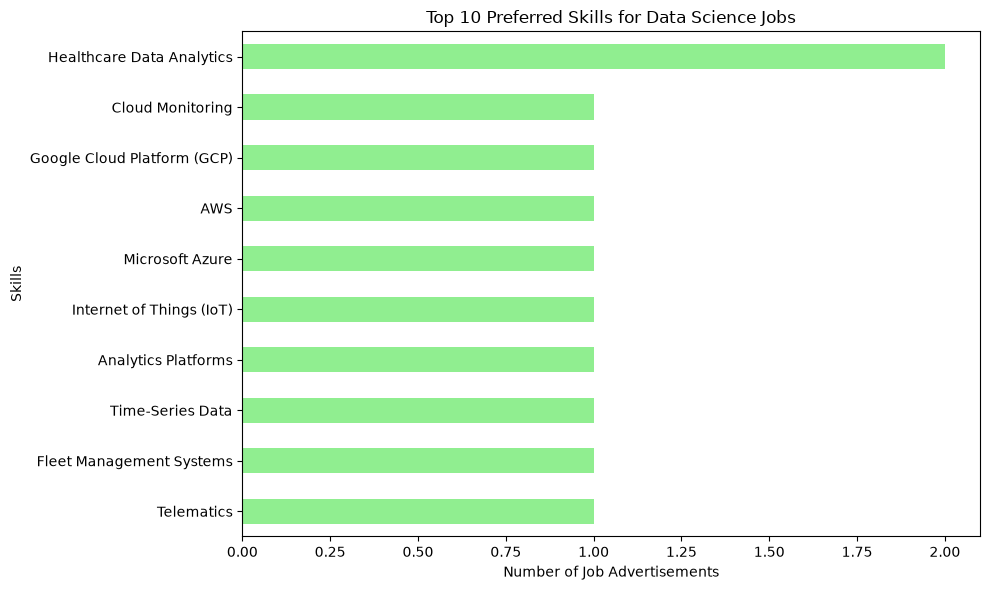

In [84]:
plt.figure(figsize=(10, 6))

top_science_preferred.sort_values().plot(
    kind="barh",
    color="lightgreen"
)

plt.title("Top 10 Preferred Skills for Data Science Jobs")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

### Top 10 Preferred Skills for Data Science Jobs

The analysis examined the preferred skills listed across Data Science job advertisements.

Healthcare Data Analytics is the most frequently mentioned preferred skill, appearing in 2 advertisements.

Other preferred skills include Telematics, Fleet Management Systems, Time-Series Data, Analytics Platforms, Microsoft Azure, Internet of Things (IoT), AWS, Google Cloud Platform and Cloud Monitoring. Each appears in 1 advertisement.

These findings suggest that employers value specialised industry knowledge, cloud technologies and experience working with different types of data.

The presence of healthcare analytics, telematics and IoT also highlights the variety of industries and applications in which Data Science skills can be used.

Overall, the results suggest that additional industry-specific and cloud technology knowledge may provide a competitive advantage for Data Science candidates.

In [85]:
category_preferred_skills = pd.DataFrame({
    "Data Analyst": top_analyst_preferred,
    "Data Engineering": top_engineering_preferred,
    "Data Science": top_science_preferred
})

category_preferred_skills

,Data Analyst,Data Engineering,Data Science
A/B Testing,2.0,NaN,NaN
AWS,NaN,NaN,1.0
Analytics Platforms,NaN,NaN,1.0
Apache Airflow,NaN,3.0,NaN
Apache Kafka,NaN,2.0,NaN
Cloud Monitoring,NaN,NaN,1.0
Data Visualisation,2.0,NaN,NaN
Financial Services Knowledge,NaN,2.0,NaN
Fleet Management Systems,NaN,NaN,1.0
Google Analytics 4 (GA4),1.0,NaN,NaN


### Comparison of Preferred Skills Across Job Categories

The comparison of preferred skills reveals differences in the additional competencies employers value across the three job categories.

Data Analyst advertisements place emphasis on business intelligence and visualisation tools, particularly Power BI, Tableau and Looker. A/B Testing and SQL also feature among the preferred skills.

Data Engineering advertisements show greater interest in data orchestration and engineering technologies, including Apache Airflow, Microsoft Fabric and Apache Kafka. Python and Financial Services Knowledge also appear among the preferred skills.

Data Science advertisements include a variety of specialised preferences, such as Healthcare Data Analytics, cloud platforms, Time-Series Data, Telematics and Internet of Things (IoT).

Power BI appears in both Data Analyst and Data Engineering advertisements, suggesting that business intelligence skills can be useful across different data career paths.

Overall, the findings indicate that preferred skills tend to reflect the specialised tools, technologies and industry knowledge associated with each job category.

In [86]:
common_preferred_all_categories = (
    set(analyst_preferred_count.keys())
    & set(engineering_preferred_count.keys())
    & set(science_preferred_count.keys())
)

print(
    "Preferred skills common to all three categories:",
    len(common_preferred_all_categories)
)

sorted(common_preferred_all_categories)

Preferred skills common to all three categories: 4


['Power BI', 'Python', 'Snowflake', 'Tableau']

In [87]:
common_preferred_comparison = pd.DataFrame({
    "Data Analyst": {
        skill: analyst_preferred_count[skill]
        for skill in common_preferred_all_categories
    },
    "Data Engineering": {
        skill: engineering_preferred_count[skill]
        for skill in common_preferred_all_categories
    },
    "Data Science": {
        skill: science_preferred_count[skill]
        for skill in common_preferred_all_categories
    }
})

common_preferred_comparison


,Data Analyst,Data Engineering,Data Science
Power BI,3,1,1
Tableau,2,1,1
Python,1,2,1
Snowflake,1,1,1


### Preferred Skills Common Across All Three Job Categories

The analysis identified four preferred skills that appear across all three job categories: Power BI, Tableau, Python and Snowflake.

Power BI appears most frequently in Data Analyst advertisements, with 3 mentions, compared to 1 mention each in Data Engineering and Data Science advertisements.

Tableau also appears more frequently in Data Analyst advertisements, with 2 mentions. Python appears most frequently in Data Engineering advertisements, with 2 mentions.

Snowflake appears once in each job category.

These findings suggest that certain tools and technologies can provide additional value across different data career paths. However, their frequency varies according to the job category.

The results also highlight the importance of distinguishing between required and preferred skills when interpreting employer expectations.

In [88]:
df["cloud_platform_list"].value_counts()

cloud_platform_list
['AWS', 'Google Cloud Platform (GCP)', 'Microsoft Azure']    5
['AWS']                                                      3
['Microsoft Azure']                                          2
['Google Cloud Platform (GCP)']                              2
['AWS', 'Microsoft Azure']                                   1
['Google Cloud Platform (GCP)', 'Microsoft Azure']           1
Name: count, dtype: int64

In [89]:
cloud_platforms = df["cloud_platform_list"].dropna().apply(ast.literal_eval)

all_cloud_platforms = [
    platform
    for platforms in cloud_platforms
    for platform in platforms
]

cloud_platform_count = Counter(all_cloud_platforms)

cloud_platform_count

Counter({'AWS': 9, 'Microsoft Azure': 9, 'Google Cloud Platform (GCP)': 8})

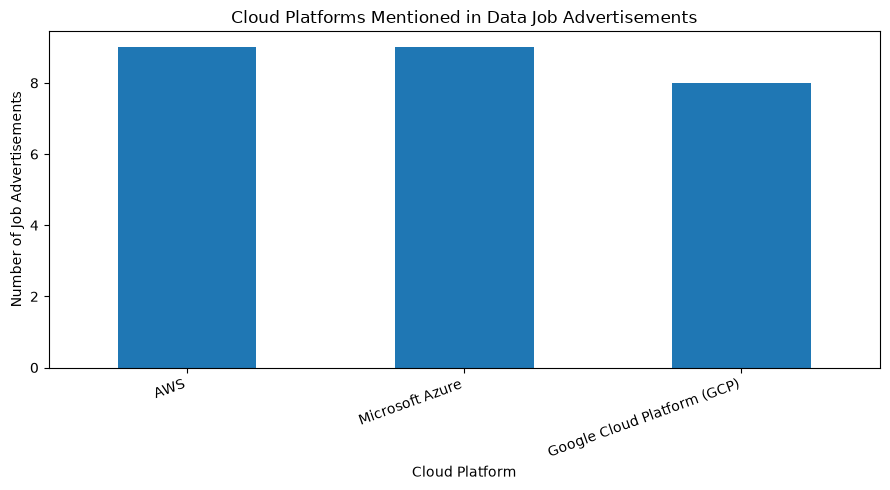

In [90]:
cloud_platform_series = pd.Series(cloud_platform_count)

cloud_platform_series.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Cloud Platforms Mentioned in Data Job Advertisements")
plt.xlabel("Cloud Platform")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Cloud Platform Analysis

The analysis examined the cloud platforms mentioned across the collected job advertisements.

AWS and Microsoft Azure are tied as the most frequently mentioned cloud platforms, each appearing in 9 advertisements. Google Cloud Platform (GCP) follows closely, appearing in 8 advertisements.

The results indicate that all three major cloud platforms are represented relatively evenly in the collected job advertisements.

This suggests that knowledge of cloud computing technologies may be valuable across different data-related career paths.

However, these counts represent platform mentions rather than exclusive usage, as individual job advertisements may mention more than one cloud platform.

In [91]:
cloud_by_category = {}

for category in df["job_category"].unique():

    category_jobs = df[df["job_category"] == category]

    category_platforms = (
        category_jobs["cloud_platform_list"]
        .dropna()
        .apply(ast.literal_eval)
    )

    all_platforms = [
        platform
        for platforms in category_platforms
        for platform in platforms
    ]

    cloud_by_category[category] = Counter(all_platforms)

cloud_by_category

{'Data Analyst': Counter(),
 'Data Engineering': Counter({'AWS': 8,
          'Microsoft Azure': 7,
          'Google Cloud Platform (GCP)': 6}),
 'Data Science': Counter({'Google Cloud Platform (GCP)': 2,
          'Microsoft Azure': 2,
          'AWS': 1})}

### Cloud Platforms Across Job Categories

The analysis examined the distribution of cloud platform mentions across Data Analyst, Data Engineering and Data Science advertisements.

Data Engineering advertisements show the highest number of cloud platform mentions. AWS is the most frequently mentioned platform, appearing 8 times, followed by Microsoft Azure (7) and Google Cloud Platform (6).

In Data Science advertisements, Microsoft Azure and Google Cloud Platform each appear twice, while AWS appears once.

No cloud platform mentions were recorded for the Data Analyst category.

These findings suggest that cloud technologies are particularly prominent in the collected Data Engineering advertisements.

However, the absence of recorded cloud platforms in Data Analyst advertisements should not be interpreted as evidence that these professionals do not use cloud technologies. The findings are limited to the information provided in the collected job advertisements.

In [92]:
cloud_category_comparison = pd.DataFrame(
    cloud_by_category
).fillna(0).astype(int)

cloud_category_comparison

,Data Analyst,Data Engineering,Data Science
AWS,0,8,1
Microsoft Azure,0,7,2
Google Cloud Platform (GCP),0,6,2


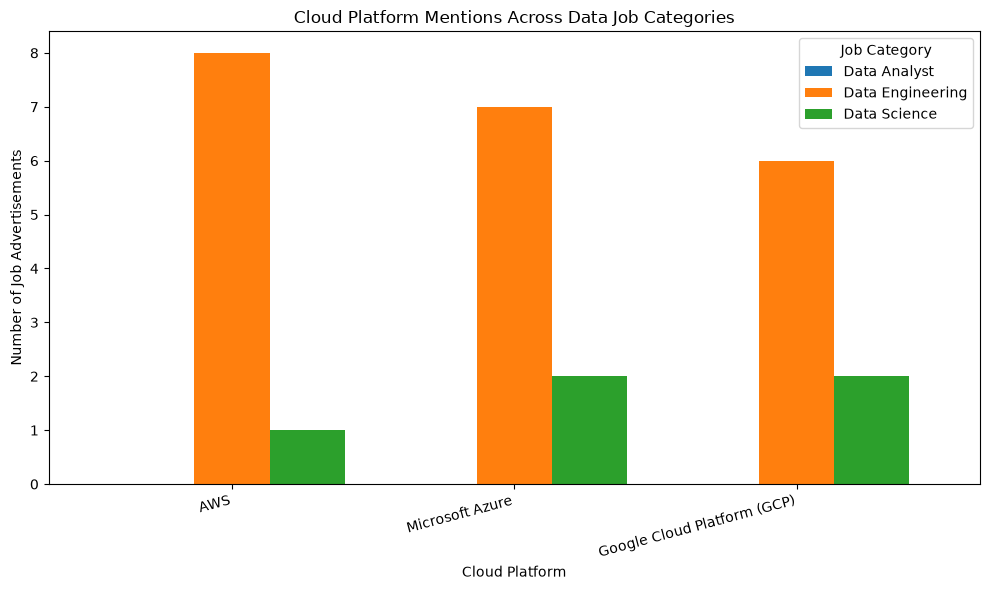

In [93]:
cloud_category_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Cloud Platform Mentions Across Data Job Categories")
plt.xlabel("Cloud Platform")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Job Category")
plt.tight_layout()
plt.show()

### Comparison of Cloud Platforms Across Job Categories

The grouped bar chart compares the frequency of AWS, Microsoft Azure and Google Cloud Platform across the three data job categories.

Data Engineering advertisements have the highest number of cloud platform mentions, with AWS appearing most frequently (8), followed by Microsoft Azure (7) and Google Cloud Platform (6).

Data Science advertisements show fewer mentions, with Microsoft Azure and Google Cloud Platform appearing twice each, while AWS appears once.

No cloud platform mentions were recorded in the Data Analyst advertisements.

Overall, the findings suggest that cloud platform knowledge is particularly prominent in the Data Engineering advertisements collected. However, the results should be interpreted within the context of the small dataset and missing cloud platform information.

In [94]:
df["seniority_level"].value_counts()


seniority_level
Senior      4
Junior      1
Graduate    1
Name: count, dtype: int64

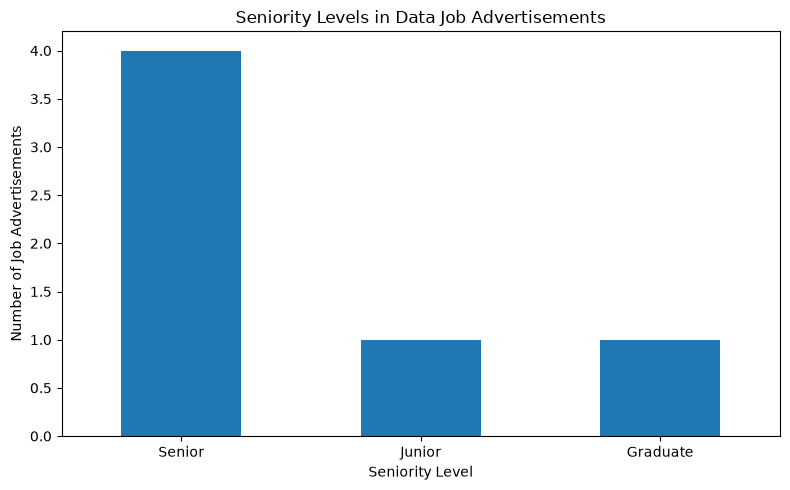

In [95]:
seniority_counts = df["seniority_level"].value_counts()

seniority_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Seniority Levels in Data Job Advertisements")
plt.xlabel("Seniority Level")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Seniority Level Analysis

The analysis examined the seniority levels specified in the collected job advertisements.

Only 6 out of the 30 advertisements included seniority-level information. Senior positions were the most frequently recorded, appearing in 4 advertisements, while Junior and Graduate positions each appeared once.

The remaining 24 advertisements (80%) did not specify a seniority level.

These findings indicate that seniority information was largely unavailable in the collected dataset. Although Senior positions were more frequently represented among the recorded entries, this should not be interpreted as evidence that the broader data job market is dominated by senior-level opportunities.

The limited number of explicitly labelled Junior and Graduate positions also highlights the difficulty of identifying entry-level opportunities using seniority labels alone.

In [96]:
df["job_title"].value_counts().head(10)

job_title
Data Engineer                            11
Data Analyst                              5
Data Scientist                            2
Junior Analytics Specialist               1
Analytics Graduate Analyst                1
Power BI and Data Insights Specialist     1
Market Analyst                            1
CX Intelligence Specialist                1
Data Analyst and Reporting Specialist     1
Developer: SQL & Reporting                1
Name: count, dtype: int64

### Most Frequently Advertised Job Titles

The analysis examined the frequency of individual job titles across the 30 collected advertisements.

Data Engineer is the most frequently advertised position, appearing in 11 advertisements. Data Analyst follows with 5 advertisements, while Data Scientist appears twice.

The remaining job titles each appear once, including Junior Analytics Specialist, Analytics Graduate Analyst, Power BI and Data Insights Specialist, and Market Analyst.

These findings demonstrate that data-related opportunities are advertised under a variety of job titles, not only traditional titles such as Data Analyst, Data Engineer and Data Scientist.

The presence of graduate and junior-specific titles also highlights the importance of searching for entry-level opportunities using different job title variations.

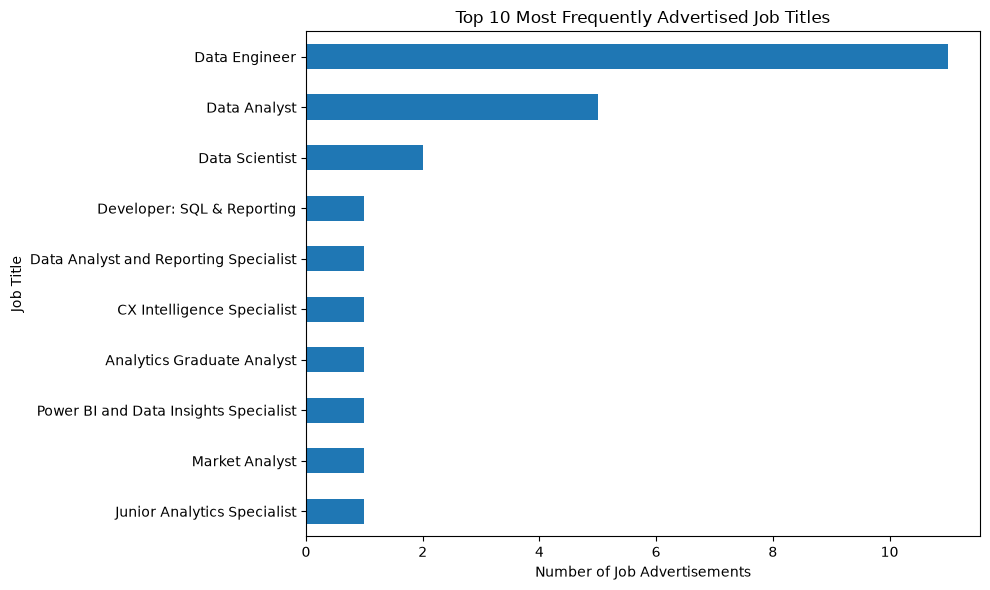

In [97]:
top_job_titles = df["job_title"].value_counts().head(10)

top_job_titles.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Most Frequently Advertised Job Titles")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

In [98]:
df["city"].value_counts()

city
Johannesburg    12
Cape Town        7
Stellenbosch     3
Durban           2
Gauteng          1
George           1
Name: count, dtype: int64

### Geographical Distribution of Data Job Advertisements

The analysis examined the geographical distribution of the collected data job advertisements across South Africa.

Johannesburg has the highest number of advertisements, with 12, followed by Cape Town with 7. Stellenbosch accounts for 3 advertisements, while Durban has 2. Gauteng and George each have 1 advertisement.

Johannesburg and Cape Town together account for approximately 73.1% of the 26 advertisements with recorded location information.

These findings suggest that the collected opportunities are concentrated primarily around Johannesburg and Cape Town.

However, four advertisements had missing location information. Additionally, Gauteng is a province rather than a city, which should be considered when interpreting the results.

The findings reflect the geographical distribution of this dataset and should not be treated as a complete representation of the South African data job market.

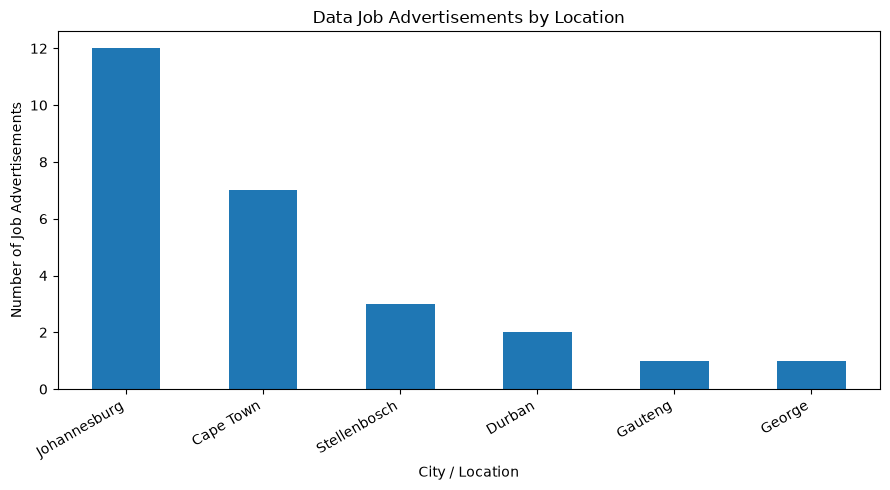

In [99]:
city_counts = df["city"].value_counts()

city_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Data Job Advertisements by Location")
plt.xlabel("City / Location")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [100]:
location_work_arrangement = pd.crosstab(
    df["city"],
    df["work_arrangement"]
)

location_work_arrangement

work_arrangement,Hybrid,On-site,Remote
city,,,
Cape Town,3,3,1
Durban,1,1,0
Gauteng,0,1,0
George,0,1,0
Johannesburg,6,6,0
Stellenbosch,1,2,0


### Job Locations and Work Arrangements

The analysis compared geographical locations with the work arrangements specified in the job advertisements.

Johannesburg has 6 hybrid and 6 on-site advertisements, making it the location with the highest number of opportunities in both arrangements.

Cape Town has 3 hybrid, 3 on-site and 1 remote advertisement. Stellenbosch has 2 on-site and 1 hybrid opportunity, while Durban has an equal number of hybrid and on-site advertisements.

Only one advertisement with a recorded city offers remote work, and it is associated with Cape Town.

These findings suggest that hybrid and on-site arrangements dominate the collected advertisements, while fully remote opportunities are limited.

The results may be useful for understanding the geographical and workplace flexibility of the advertised opportunities. However, they reflect only the collected sample.

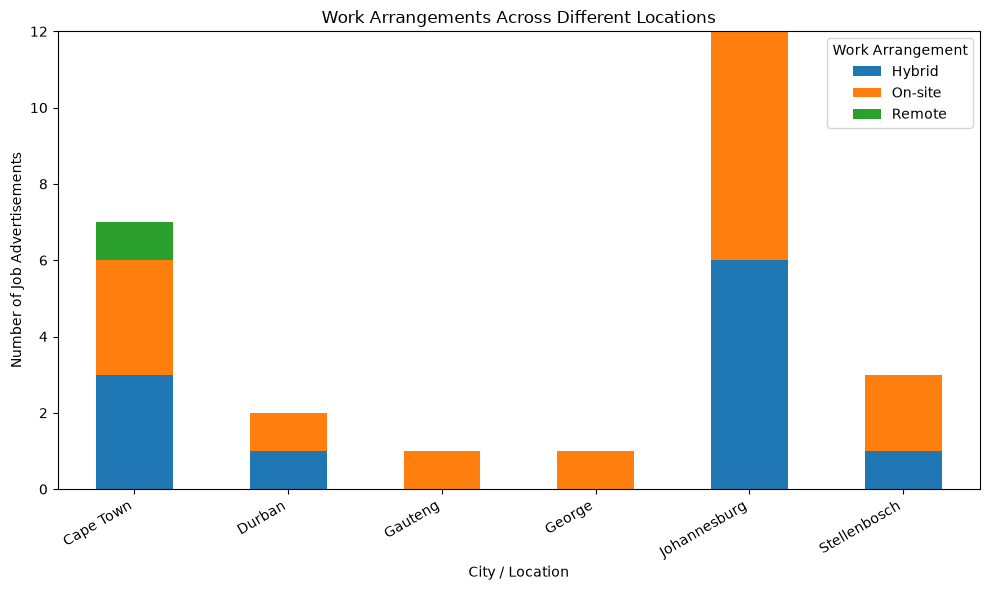

In [101]:
location_work_arrangement.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Work Arrangements Across Different Locations")
plt.xlabel("City / Location")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Work Arrangement")
plt.tight_layout()
plt.show()

In [102]:
df[["job_title", "salary_min", "salary_max", "basic_salary", "salary_period", "currency"]]


,job_title,salary_min,salary_max,basic_salary,salary_period,currency
0,Junior Analytics Specialist,13600.0,20400.0,NaN,Monthly,USD
1,Data Analyst,NaN,NaN,25000.0,Monthly,ZAR
2,Data Analyst,550.0,700.0,NaN,Hourly,ZAR
3,Analytics Graduate Analyst,NaN,NaN,NaN,NaN,NaN
4,Data Analyst,NaN,NaN,NaN,NaN,NaN
5,Power BI and Data Insights Specialist,NaN,NaN,NaN,NaN,NaN
6,Market Analyst,NaN,NaN,NaN,NaN,NaN
7,CX Intelligence Specialist,NaN,NaN,NaN,NaN,NaN
8,Data Analyst,NaN,NaN,NaN,NaN,NaN
9,Data Analyst and Reporting Specialist,NaN,NaN,NaN,NaN,NaN


### Salary Information Analysis

The analysis examined salary information across the 30 collected job advertisements.

Only 3 advertisements contained salary information. Two provided minimum and maximum salary ranges, while one provided a basic salary.

The available salary information included monthly and hourly payment periods, with salaries reported in both South African Rand (ZAR) and United States Dollars (USD).

The remaining 27 advertisements did not disclose salary information.

These findings highlight a significant limitation in the dataset, as the limited number of salary records makes it difficult to identify reliable salary trends or compare earnings across different data career categories.

An overall salary comparison would also be inappropriate without accounting for differences in currencies and payment periods.

In [103]:
salary_columns = [
    "salary_min",
    "salary_max",
    "basic_salary",
    "salary_period",
    "currency"
]

df[salary_columns].isnull().sum()

salary_min       28
salary_max       28
basic_salary     29
salary_period    27
currency         27
dtype: int64

### Missing Salary Information

The missing-value analysis revealed substantial gaps in the salary-related columns.

Salary minimum and maximum each contain 28 missing values (93.3%), while basic salary contains 29 missing values (96.7%).

Salary period and currency each contain 27 missing values (90%).

These results indicate that salary transparency is limited in the collected job advertisements.

The high proportion of missing salary information prevents reliable comparisons of compensation across job categories and highlights an important limitation of the dataset.

In [104]:
df["qualification"].value_counts().head(15)

qualification
BCom Informatics, BSc Computer Science,BSc Data Science                                                                                                                                                                                                                                           1
Relevant Analytics or Design Qualification                                                                                                                                                                                                                                                        1
Relevant Quantitative Qualification or Equivalent Demonstrated Capability                                                                                                                                                                                                                         1
Bachelor's Degree or Diploma in Data Analytics, Statistics, Mathematics, Business Intelligence, Information Sy

### Educational Qualification Analysis

The analysis examined the educational qualifications specified in the collected job advertisements.

The qualification descriptions were highly varied, with each exact description appearing only once.

Despite the variation in wording, several recurring educational themes were identified. These include Computer Science, Information Technology, Information Systems, Mathematics, Statistics, Data Analytics and Data Science.

Some advertisements also accept related business and quantitative qualifications, including Economics, Marketing Analytics and Business Intelligence.

The findings suggest that employers consider a range of educational backgrounds relevant to data-related careers, particularly qualifications involving computing, mathematics, statistics and analytical disciplines.

However, because the descriptions differ considerably, exact frequency counts cannot reliably identify the most commonly requested qualification.


In [105]:
df["experience"].value_counts()

experience
5+    8
3+    7
4+    3
1+    2
7+    2
0+    1
2+    1
8+    1
6+    1
Name: count, dtype: int64

### Work Experience Requirements

The analysis examined the experience requirements specified in the collected job advertisements.

Out of 30 advertisements, 26 included experience information, while 4 had missing values.

The most frequently requested experience level is 5+ years, appearing in 8 advertisements, followed by 3+ years, appearing in 7 advertisements. Requirements of 4+ years appear in 3 advertisements.

Only 3 advertisements specify experience requirements of 0+, 1+ or 2+ years combined.

These findings suggest that many employers in the collected sample seek candidates with several years of professional experience.

The relatively low number of advertisements with limited experience requirements may indicate challenges for graduates and individuals entering the data industry.

However, experience requirements alone do not establish whether a position is suitable for entry-level candidates.

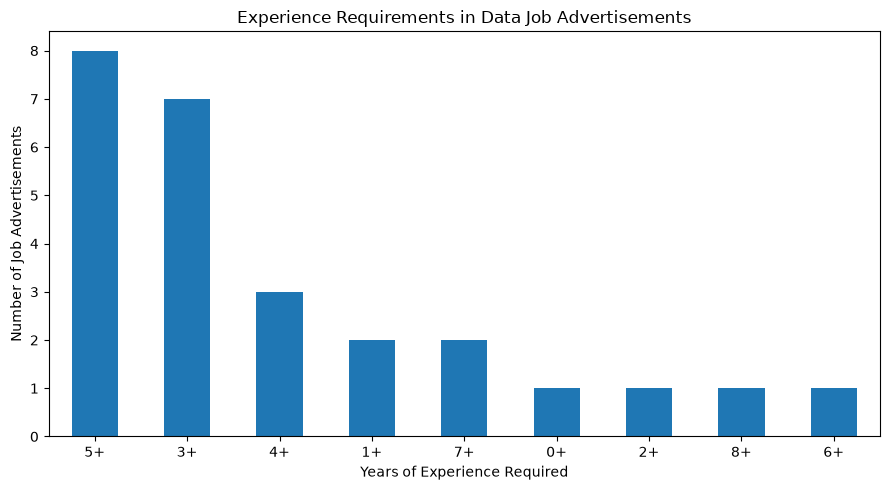

In [106]:
experience_counts = df["experience"].value_counts()

experience_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Experience Requirements in Data Job Advertisements")
plt.xlabel("Years of Experience Required")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [107]:
employment_by_category = pd.crosstab(
    df["job_category"],
    df["employment_type"]
)

employment_by_category

employment_type,Contract,Full-Time
job_category,,
Data Analyst,1,10
Data Engineering,0,13
Data Science,0,6


### Employment Types Across Job Categories

The analysis compared employment types across Data Analyst, Data Engineering and Data Science advertisements.

Data Engineering has 13 Full-Time advertisements, while Data Science has 6. Data Analyst has 10 Full-Time advertisements and 1 Contract opportunity.

Overall, 29 out of the 30 advertisements (96.7%) offer Full-Time employment, while only 1 (3.3%) is a Contract position.

These findings indicate that Full-Time employment dominates the collected advertisements across all three job categories.

However, the small number of contract opportunities limits comparisons between employment types.

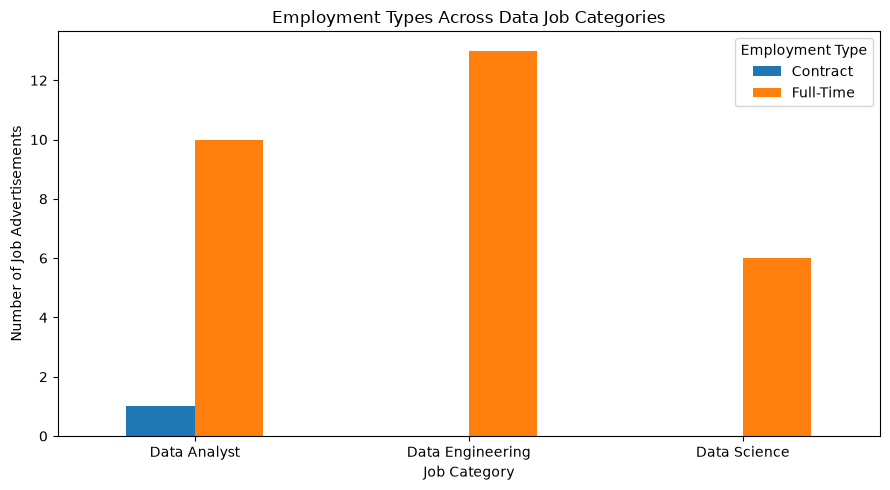

In [108]:
employment_by_category.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Employment Types Across Data Job Categories")
plt.xlabel("Job Category")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.legend(title="Employment Type")
plt.tight_layout()
plt.show()


In [109]:
df["date_posted"].value_counts()

date_posted
2 weeks ago     10
1 month ago      6
1 week ago       4
1 day ago        4
3 weeks ago      3
2 months ago     1
4 days ago       1
2 days ago       1
Name: count, dtype: int64

### Job Posting Date Analysis

The analysis examined the distribution of job advertisements according to their recorded posting dates.

The largest number of advertisements (10) was posted 2 weeks ago, followed by 6 advertisements posted 1 month ago.

Four advertisements were posted 1 week ago, while another 4 were posted 1 day ago. The remaining advertisements were distributed across other posting periods, including 2 days, 4 days, 3 weeks and 2 months ago.

These findings indicate that the collected dataset contains a mixture of recently posted and older job opportunities, with the largest concentration of advertisements posted approximately two weeks before data collection.

However, the posting dates are recorded as relative text values rather than exact dates, which limits more detailed time-based analysis.

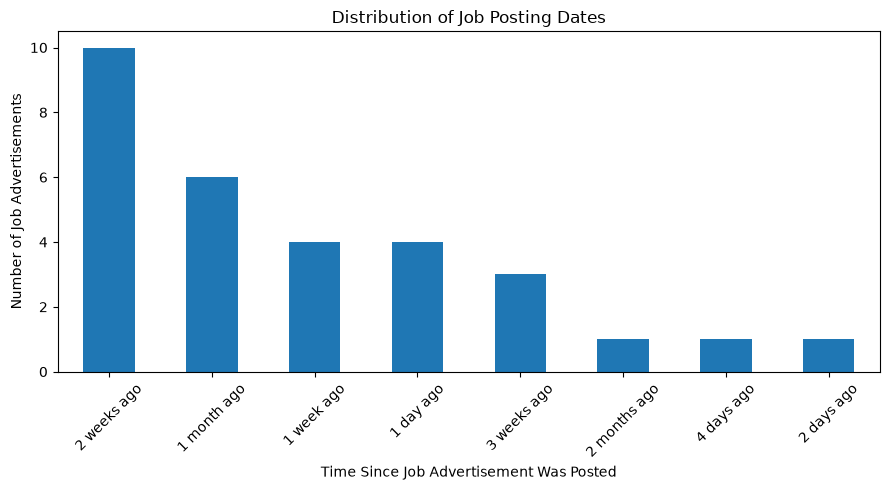

In [110]:
date_counts = df["date_posted"].value_counts()

date_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Job Posting Dates")
plt.xlabel("Time Since Job Advertisement Was Posted")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [111]:
experience_by_category = pd.crosstab(
    df["job_category"],
    df["experience"]
)

experience_by_category

experience,0+,1+,2+,3+,4+,5+,6+,7+,8+
job_category,,,,,,,,,
Data Analyst,1,1,0,3,0,4,0,0,0
Data Engineering,0,0,1,4,2,2,1,1,1
Data Science,0,1,0,0,1,2,0,1,0


### Experience Requirements Across Job Categories

The analysis compared experience requirements across Data Analyst, Data Engineering and Data Science advertisements.

For Data Analyst positions, 5+ years is the most frequently requested experience level, appearing in 4 advertisements. Three advertisements request 3+ years, while two specify 0+ or 1+ years.

Data Engineering advertisements show a wider distribution of experience requirements. The most common requirement is 3+ years, appearing in 4 advertisements. Other advertisements request experience ranging from 2+ to 8+ years.

For Data Science positions, 5+ years is the most frequently recorded requirement, appearing in 2 advertisements. Other requirements include 1+, 4+ and 7+ years.

Overall, the findings suggest that several years of professional experience are commonly requested across the three data career categories.

However, the dataset contains only 30 advertisements, and four have missing experience information. These findings should therefore be interpreted as patterns within the collected sample rather than the entire South African data job market.

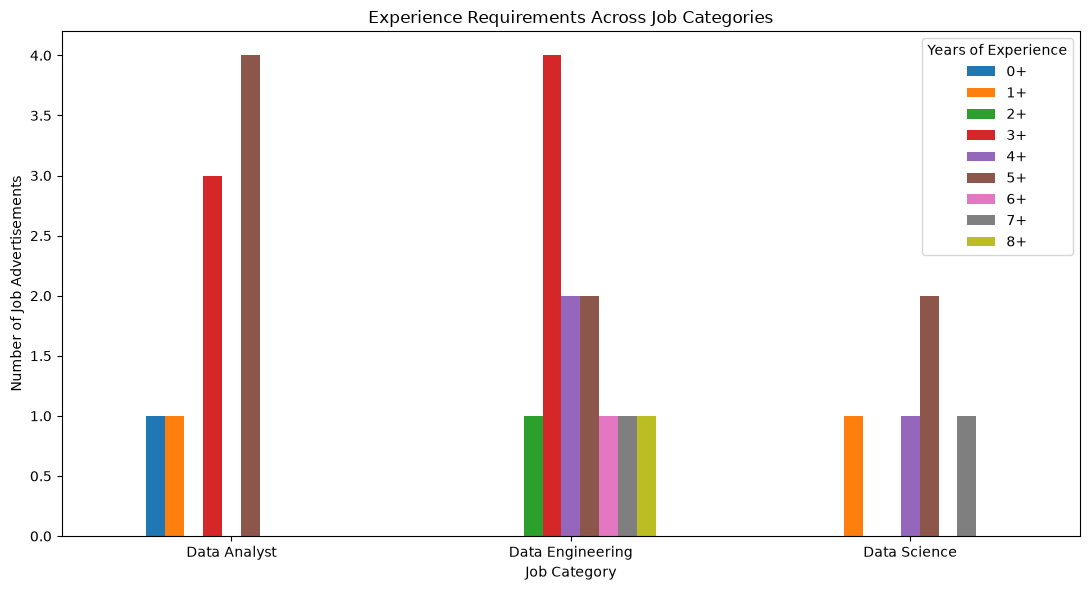

In [112]:
experience_by_category.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Experience Requirements Across Job Categories")
plt.xlabel("Job Category")
plt.ylabel("Number of Job Advertisements")
plt.xticks(rotation=0)
plt.legend(title="Years of Experience")
plt.tight_layout()
plt.show()

In [113]:
import os
os.getcwd()


'c:\\Users\\Sinovuyo Busakwe\\Downloads\\job-market-skills-analysis-main\\notebooks'

In [114]:
import os

os.path.exists("../.git")

True

In [115]:
import os
from datetime import datetime

notebook_path = "../01_data_cleaning.ipynb"

datetime.fromtimestamp(
    os.path.getmtime(notebook_path)
)


FileNotFoundError: [WinError 2] The system cannot find the file specified: '../01_data_cleaning.ipynb'

In [116]:
import os
from datetime import datetime

notebook_path = "../01_data_cleaning.ipynb"

datetime.fromtimestamp(
    os.path.getmtime(notebook_path)
)


FileNotFoundError: [WinError 2] The system cannot find the file specified: '../01_data_cleaning.ipynb'

In [117]:
import os
from datetime import datetime

notebook_path = "01_data_cleaning.ipynb"

print("File exists:", os.path.exists(notebook_path))

print(
    "Last modified:",
    datetime.fromtimestamp(os.path.getmtime(notebook_path))
)


File exists: True
Last modified: 2026-11-24 14:09:47.710916


In [118]:
import os
from datetime import datetime

path = "01_data_cleaning.ipynb"

print(os.path.abspath(path))
print(datetime.fromtimestamp(os.path.getmtime(path)))

c:\Users\Sinovuyo Busakwe\Downloads\job-market-skills-analysis-main\notebooks\01_data_cleaning.ipynb
2026-11-24 14:09:47.710916


In [119]:
import os

print(os.listdir())


['01_data_cleaning.ipynb', '02_exploratory_data_analysis.ipynb']


In [120]:
from datetime import datetime
import os

notebook_path = "02_exploratory_data_analysis.ipynb"

print("File exists:", os.path.exists(notebook_path))

print(
    "Last modified:",
    datetime.fromtimestamp(os.path.getmtime(notebook_path))
)

File exists: True
Last modified: 2026-11-24 16:52:27.876131


In [121]:
import os

print(os.path.abspath("02_exploratory_data_analysis.ipynb"))

c:\Users\Sinovuyo Busakwe\Downloads\job-market-skills-analysis-main\notebooks\02_exploratory_data_analysis.ipynb


In [1]:
import os

print(os.path.abspath("02_exploratory_data_analysis.ipynb"))

c:\Users\Sinovuyo Busakwe\Downloads\job-market-skills-analysis\notebooks\02_exploratory_data_analysis.ipynb


In [2]:
import os

print(os.getcwd())


c:\Users\Sinovuyo Busakwe\Downloads\job-market-skills-analysis\notebooks
